# Exploratory Data Analysis: Retail Customer Sales Data
**Data Analyst Training Program | Mini Project 1**

**Name:** Lakshay Malik  |  **Program:** MCA, First Year  |  **Admission No.:** 2026M0141 0097  |  **Instructor:** Mr. Amit Bhatnagar  |  **Date:** 23/11/2026

**Goal:** audit the quality of the retail sales dataset, clean it with a reason for every decision, describe what it contains, and answer a few business questions from it.

**Flow of this notebook** (same order as the project brief)
1. Setup and first look
2. Data quality audit
3. Data cleaning
4. Descriptive statistics and univariate analysis
5. Outlier detection
6. Feature engineering and business questions
7. Summary

## 1. Setup and first look

In [1]:
# --- Libraries (all four are the ones listed in the brief) ---
import pandas as pd              # load, clean and group tabular data
import numpy as np               # numbers, NaN handling, z-score maths
import matplotlib.pyplot as plt  # base plotting
import seaborn as sns            # nicer statistical plots (hist, box, bar)
import json, os                  # json: save key numbers for the report; os: make folders
import warnings
warnings.filterwarnings("ignore")   # keeps the output clean (only harmless version warnings)

# (optional library not used) missingno could draw the missing-value pattern;
# I drew it with plain matplotlib instead so there is nothing extra to install.

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# one simple look for every chart
sns.set_theme(style="whitegrid", font_scale=1.0)
BLUE, ORANGE, TEAL, PURPLE, GREY = "#2F5D8A", "#E08A2E", "#2A9D8F", "#7B5EA7", "#8A8F98"
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

KEY = {}   # dictionary where I collect headline numbers for the written report

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
raw = pd.read_csv("retail_customer_sales_dataset.csv")
print("Shape:", raw.shape)
print("\nColumns:", list(raw.columns))
KEY["raw_rows"], KEY["raw_cols"] = raw.shape

Shape: (7084, 24)

Columns: ['Transaction_ID', 'Customer_ID', 'Order_Date', 'Delivery_Date', 'Age', 'Gender', 'Income', 'Region', 'State', 'City', 'Customer_Segment', 'Product_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Payment_Method', 'Delivery_Mode', 'Customer_Rating', 'Satisfaction_Level', 'Returned']


In [3]:
raw.dtypes

Transaction_ID            str
Customer_ID               str
Order_Date                str
Delivery_Date             str
Age                   float64
Gender                    str
Income                float64
Region                    str
State                     str
City                      str
Customer_Segment          str
Product_Category          str
Product                   str
Quantity                int64
Unit_Price            float64
Discount              float64
Sales                 float64
Cost                  float64
Profit                float64
Payment_Method            str
Delivery_Mode             str
Customer_Rating       float64
Satisfaction_Level        str
Returned                  str
dtype: object

In [4]:
raw.head()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.00,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.00,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.00,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.00,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.00,Female,"95,727.49",north,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No


In [5]:
raw.tail()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7079,TXN201768,CUST10870,2024-10-22,2024-10-27,34.00,Male,"79,446.58",East,Odisha,Bhubaneswar,Corporate,Electronics,Laptop Stand,1,"5,395.38",0.09,"4,909.80","3,273.47","1,636.33",Net Banking,Express,2.00,Low,Yes
7080,TXN201737,CUST10314,2024-10-05,2024-10-14,50.00,Male,"21,796.92",East,West Bengal,Durgapur,Home Office,Clothing,Formal Shirt,3,"1,603.82",0.02,"4,715.23","2,923.68","1,791.55",Credit Card,Standard,4.00,High,No
7081,TXN203240,CUST10859,2024-06-04,2024-06-15,42.00,Male,"60,621.27",West,Gujarat,Surat,Consumer,Electronics,Laptop Stand,1,"11,519.59",0.22,"8,985.28","5,360.01","3,625.27",UPI,Standard,2.00,Medium,No
7082,TXN205305,CUST10829,2024-03-31,2024-04-08,32.00,Female,"42,178.47",South,Kerala,Kozhikode,Consumer,Clothing,Running Shoes,3,980.67,0.21,"2,324.19","1,812.17",512.02,UPI,Standard,4.00,High,No
7083,TXN204737,CUST10847,2024-10-18,2024-10-26,63.00,Male,"44,113.29",South,Kerala,Kozhikode,Consumer,Clothing,Denim Jacket,2,"3,727.59",0.30,"5,218.63","3,932.52","1,286.11",Debit Card,Standard,4.00,High,No


In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   str    
 1   Customer_ID         7084 non-null   str    
 2   Order_Date          7084 non-null   str    
 3   Delivery_Date       6978 non-null   str    
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   str    
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   str    
 8   State               7084 non-null   str    
 9   City                7084 non-null   str    
 10  Customer_Segment    7084 non-null   str    
 11  Product_Category    7084 non-null   str    
 12  Product             7084 non-null   str    
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount            7013 non-null   float64
 16  Sales            

**First impressions:** 7,084 rows and 24 columns. Both date columns are read as plain text (strings), which already hints at format problems. `Age`, `Income`, `Discount`, `Customer_Rating` and `Delivery_Date` show fewer than 7,084 non-null values, so there are missing values to deal with.

## 2. Data quality audit
I only *look* in this section. Nothing is changed here; all fixes happen in Section 3.

### 2.1 Missing values

                    missing_count  missing_pct
Customer_Rating               428         6.04
Income                        253         3.57
Satisfaction_Level            179         2.53
Age                           142         2.00
Delivery_Date                 106         1.50
Discount                       71         1.00


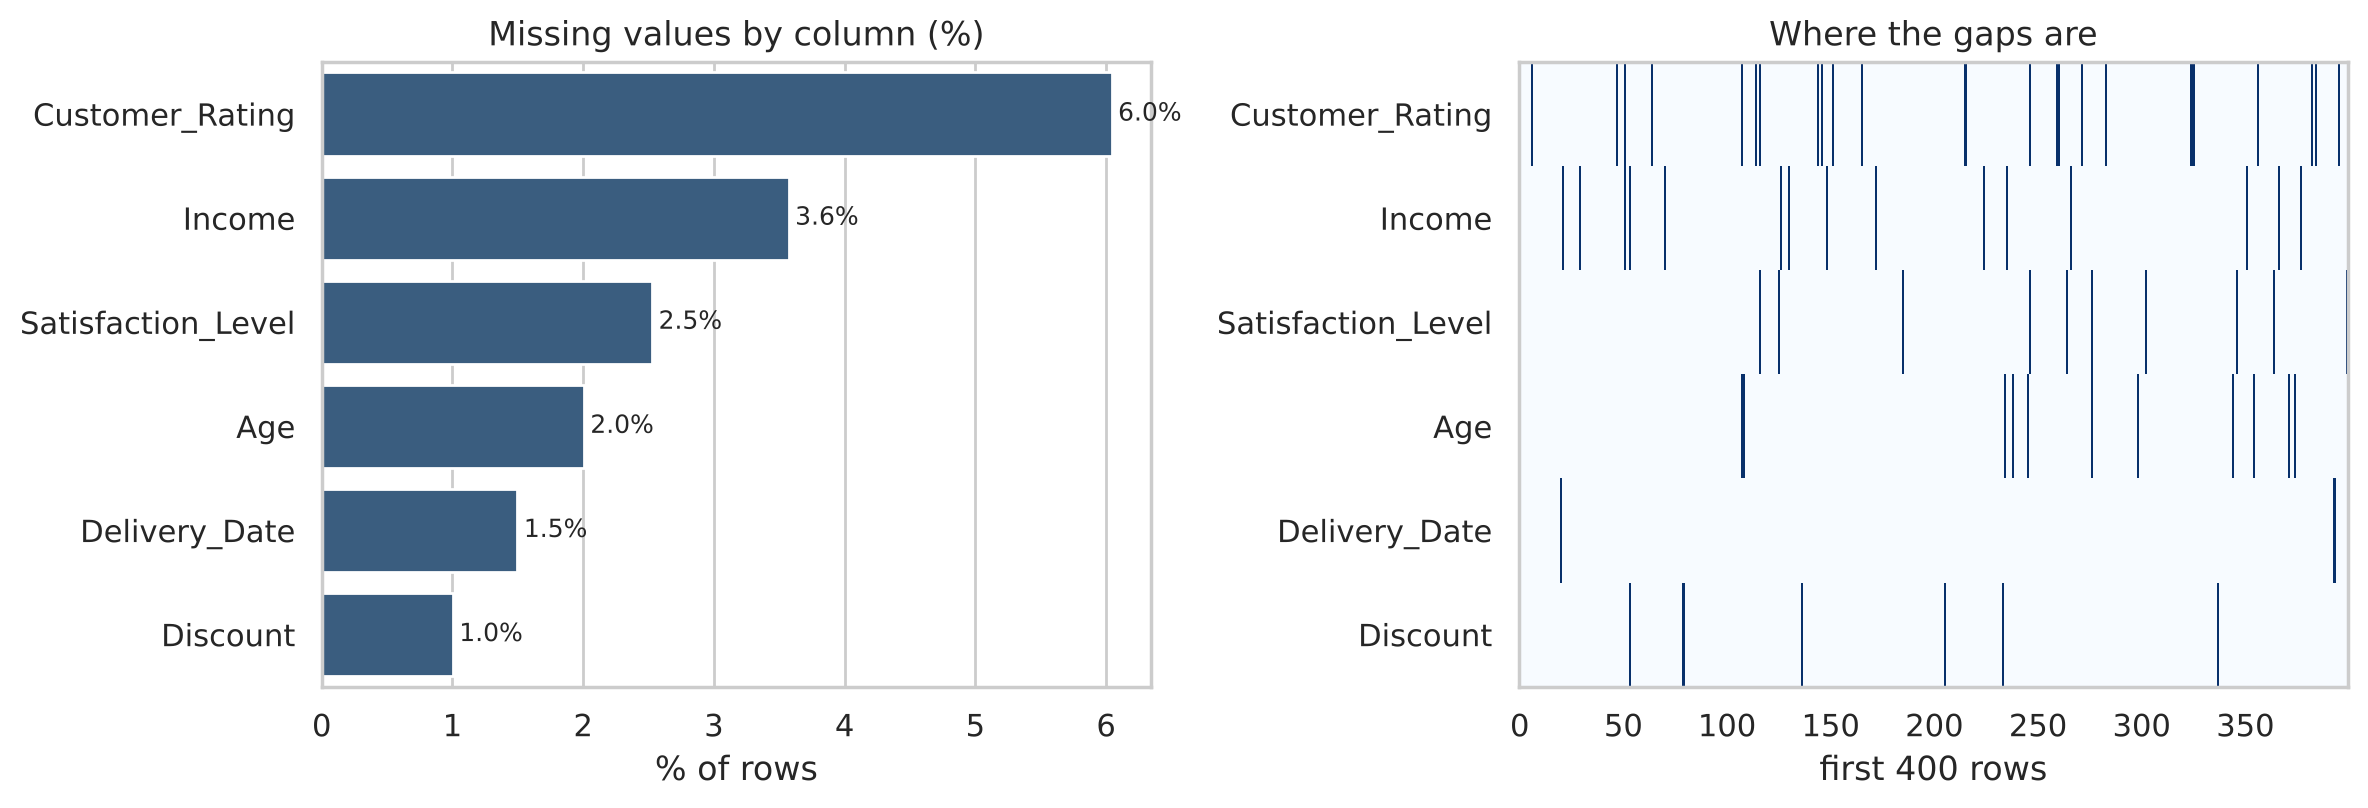

In [7]:
miss = pd.DataFrame({"missing_count": raw.isna().sum(),
                     "missing_pct": raw.isna().mean() * 100})
miss = miss[miss.missing_count > 0].sort_values("missing_count", ascending=False)
print(miss)
KEY["missing"] = {k: int(v) for k, v in miss.missing_count.items()}
KEY["missing_pct"] = {k: round(float(v), 2) for k, v in miss.missing_pct.items()}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(x=miss.missing_pct, y=miss.index, color=BLUE, ax=ax[0])
ax[0].set_title("Missing values by column (%)"); ax[0].set_xlabel("% of rows"); ax[0].set_ylabel("")
for i, v in enumerate(miss.missing_pct):
    ax[0].text(v + 0.05, i, f"{v:.1f}%", va="center", fontsize=9)

# simple missing-data map: each dark line is a missing cell (first 400 rows)
ax[1].imshow(raw[miss.index].head(400).isna().T, aspect="auto", cmap="Blues", interpolation="nearest")
ax[1].set_yticks(range(len(miss))); ax[1].set_yticklabels(miss.index)
ax[1].set_xlabel("first 400 rows"); ax[1].set_title("Where the gaps are"); ax[1].grid(False)
save("01_missing_values")

**Reading:** `Customer_Rating` has the most gaps (about 6%), which makes sense because not every buyer leaves a rating. The gaps in the other columns look scattered randomly across rows, not clustered, so they look like ordinary data-entry misses.

### 2.2 Duplicate rows

In [8]:
exact_dups = raw.duplicated().sum()
id_dups = raw.Transaction_ID.duplicated().sum()
print("Exact duplicate rows            :", exact_dups)
print("Repeated Transaction_IDs        :", id_dups)

# Transaction_ID should be unique. Rows that share an ID but are NOT exact copies - why?
same_id = raw[raw.Transaction_ID.duplicated(keep=False) & ~raw.duplicated(keep=False)].sort_values("Transaction_ID")
print("\nRows sharing an ID but not exact copies:", len(same_id))
same_id[["Transaction_ID", "Order_Date", "Delivery_Date", "Product", "Sales"]].head(6)

Exact duplicate rows            : 61
Repeated Transaction_IDs        : 84

Rows sharing an ID but not exact copies: 46


,Transaction_ID,Order_Date,Delivery_Date,Product,Sales
1227,TXN200162,22/07/2024,26/07/2024,A4 Paper Ream,"3,938.61"
1386,TXN200162,2024-07-22,2024-07-26,A4 Paper Ream,"3,938.61"
3392,TXN200221,2023-06-23,2023-06-29,Winter Jacket,"2,468.85"
6761,TXN200221,2023-06-23,2023-06-29,Winter Jacket,"2,468.85"
3719,TXN200275,30/06/2024,03/07/2024,Denim Jacket,"10,789.70"
2682,TXN200275,30-Jun-2024,03-Jul-2024,Denim Jacket,"10,789.70"


In [9]:
# Check: do they differ only in formatting (date style, upper/lower case, abbreviations)?
# Quick test: lower-case the text columns and drop the two date columns, then compare again.
tmp = raw.copy()
for c in tmp.columns:
    if pd.api.types.is_string_dtype(tmp[c]):      # text columns only (works on pandas 2 and 3)
        tmp[c] = tmp[c].str.lower().str.strip()
tmp = tmp.drop(columns=["Order_Date", "Delivery_Date", "Gender", "Region"])
print("Repeated IDs that are identical once dates, Gender and Region are ignored:",
      same_id.index.isin(tmp[tmp.duplicated(keep=False)].index).sum(), "of", len(same_id))
KEY["exact_dups"], KEY["id_dups"], KEY["id_dups_hidden"] = int(exact_dups), int(id_dups), int(id_dups - exact_dups)

Repeated IDs that are identical once dates, Gender and Region are ignored: 46 of 46


**Reading:** 61 rows are exact copies. A further 23 repeated IDs are *hidden* duplicates: every other field is identical, but the date was typed in a different format (e.g. `22/07/2024` vs `2024-07-22`) or Gender/Region was spelled differently (`female` vs `Female`, `NORTH` vs `North`). A plain `duplicated()` call misses them. So the order matters: fix dates and categories **first**, remove duplicates **after**.

### 2.3 Inconsistent categories

In [10]:
print(raw.Gender.value_counts(), "\n")
print(raw.Region.value_counts())
KEY["gender_variants"] = int(raw.Gender.nunique()); KEY["region_variants"] = int(raw.Region.nunique())

Gender
Female    3585
Male      3232
FEMALE      53
female      53
male        46
MALE        44
M           38
F           33
Name: count, dtype: int64 

Region
West     1783
East     1754
South    1741
North    1647
east       30
south      24
north      21
Sth        20
WEST       19
Nort       17
west       15
NORTH      13
Name: count, dtype: int64


In [11]:
# are the other text columns clean?
for c in ["Customer_Segment", "Product_Category", "Payment_Method", "Delivery_Mode", "Satisfaction_Level", "Returned"]:
    print(c, "->", sorted(raw[c].dropna().unique()))

Customer_Segment -> ['Consumer', 'Corporate', 'Home Office']
Product_Category -> ['Clothing', 'Electronics', 'Furniture', 'Grocery', 'Office Supplies']
Payment_Method -> ['Cash on Delivery', 'Credit Card', 'Debit Card', 'Net Banking', 'UPI']
Delivery_Mode -> ['Express', 'Same-Day', 'Standard']
Satisfaction_Level -> ['High', 'Low', 'Medium']
Returned -> ['No', 'Yes']


**Reading:** `Gender` has 8 spellings for 2 values (`Male`, `MALE`, `male`, `M`, ...). `Region` has 12 spellings for 4 regions, including truncated ones (`Nort`, `Sth`). The other categorical columns are already consistent.

### 2.4 Impossible or out-of-range values

In [12]:
print("Age < 18            :", (raw.Age < 18).sum(), "->", sorted(raw.Age[raw.Age < 18].tolist()))
print("Age > 100           :", (raw.Age > 100).sum(), "->", sorted(raw.Age[raw.Age > 100].tolist()))
print("Discount < 0        :", (raw.Discount < 0).sum(), "->", sorted(raw.Discount[raw.Discount < 0].tolist()))
print("Discount > 0.5      :", (raw.Discount > 0.5).sum(), "->", sorted(raw.Discount[raw.Discount > 0.5].tolist()))
print("Quantity <= 0       :", (raw.Quantity <= 0).sum())
print("Unit_Price <= 0     :", (raw.Unit_Price <= 0).sum())
print("Sales/Cost/Profit<0 :", ((raw.Sales < 0) | (raw.Cost < 0) | (raw.Profit < 0)).sum())
print("Rating outside 1-5  :", ((raw.Customer_Rating < 1) | (raw.Customer_Rating > 5)).sum())

# does Sales = Quantity x Unit_Price x (1 - Discount) hold, as the data dictionary says?
expected = raw.Quantity * raw.Unit_Price * (1 - raw.Discount)
mismatch = (expected - raw.Sales).abs() > 1
print("\nSales formula mismatches (> Rs 1):", mismatch.sum())
raw.loc[mismatch, ["Quantity", "Unit_Price", "Discount", "Sales"]]

Age < 18            : 3 -> [-12.0, -5.0, -1.0]
Age > 100           : 3 -> [150.0, 180.0, 999.0]
Discount < 0        : 2 -> [-0.2, -0.1]
Discount > 0.5      : 4 -> [1.1, 1.2, 1.5, 2.0]
Quantity <= 0       : 0
Unit_Price <= 0     : 0
Sales/Cost/Profit<0 : 0
Rating outside 1-5  : 0

Sales formula mismatches (> Rs 1): 6


,Quantity,Unit_Price,Discount,Sales
1196,3,"2,084.63",-0.20,"4,252.65"
2624,5,"12,394.56",2.00,"55,155.79"
3165,4,977.82,1.10,"3,598.38"
4174,4,"9,160.38",1.50,"33,343.78"
5410,3,324.04,-0.10,505.50
6693,5,"1,052.47",1.20,"5,209.73"


In [13]:
# Interesting: the mismatches are exactly the rows with invalid Discount.
# So the Sales value is right and the Discount is what got corrupted.
bad_disc = (raw.Discount < 0) | (raw.Discount > 0.5)
print("Invalid discount rows:", bad_disc.sum(), "| same rows as mismatches:", (bad_disc == mismatch).all())

# And on all the valid rows, can I recompute Discount from Sales exactly?
recalc = (1 - raw.Sales / (raw.Quantity * raw.Unit_Price)).round(2)
ok = raw.Discount.between(0, 0.5)
print("Recomputed discount equals recorded discount on valid rows:", (recalc[ok] == raw.Discount[ok]).mean() * 100, "%")
KEY["bad_age"] = int(((raw.Age < 18) | (raw.Age > 100)).sum()); KEY["bad_discount"] = int(bad_disc.sum())

Invalid discount rows: 6 | same rows as mismatches: True
Recomputed discount equals recorded discount on valid rows: 100.0 %


**Reading:**
- `Age`: three negative values (-12, -5, -1) and three impossible high values (150, 180, 999).
- `Discount`: six invalid values (-0.2, -0.1, 1.1, 1.2, 1.5, 2.0).
- The Sales formula breaks on exactly those six rows, and on every valid row it holds perfectly, so a discount can be **rebuilt exactly** as `1 - Sales / (Quantity x Unit_Price)`. That is far better than guessing a median discount. This also works for the 71 *missing* discounts.

In [14]:
# INCOME belongs to the customer, not to the order, so one customer should have ONE income.
# Is that true in the data?
n_inc = raw.groupby("Customer_ID").Income.nunique()
multi = n_inc[n_inc > 1].index
print("Customers with more than one different income:", len(multi))

chk = raw[raw.Customer_ID.isin(multi)].groupby("Customer_ID").Income.agg(["min", "max", "count"])
chk["max_vs_min"] = chk["max"] / chk["min"]
print(chk.round(2))
KEY["income_inconsistent_customers"] = int(len(multi))

# the same check on the other customer-level columns
for col in ["Age", "Gender", "Region"]:
    print(col, "-> customers with more than one value:", int((raw.groupby("Customer_ID")[col].nunique() > 1).sum()))

Customers with more than one different income: 9
                   min          max  count  max_vs_min
Customer_ID                                           
CUST10006    51,802.91   622,289.57      4       12.01
CUST10144    32,295.76   412,791.60      6       12.78
CUST10285    55,607.45   595,873.84      2       10.72
CUST10770    45,699.65   606,984.57      6       13.28
CUST10854    66,630.88   721,081.66      6       10.82
CUST10946    26,372.37   333,322.44      3       12.64
CUST11124   118,558.79 1,750,890.41      2       14.77
CUST11171    35,032.79   473,561.95      8       13.52
CUST11202    57,377.64   598,321.39      3       10.43
Age -> customers with more than one value: 6
Gender -> customers with more than one value: 240
Region -> customers with more than one value: 152


**Reading:** nine customers have two different incomes. In every case the odd value sits on a *single* order and is 10 to 15 times the customer's income on all their other orders (for example 51,803 on three orders but 622,290 on one). A person's income does not jump tenfold for one purchase, so these look like typing or scale errors, not rich customers. Age, Gender and Region are consistent per customer apart from the invalid ages and spelling variants already found (Gender and Region differences are only spelling, and Age differences are the invalid values).

### 2.5 Date formats and date logic

In [15]:
def pattern(s):
    # turns every digit into 9 so I can see the shape of each date string
    return s.dropna().str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]{3}", "Mon", regex=True)

print("Order_Date formats:\n", pattern(raw.Order_Date).value_counts(), "\n")
print("Delivery_Date formats:\n", pattern(raw.Delivery_Date).value_counts())

Order_Date formats:
 Order_Date
9999-99-99     6601
99-Mon-9999     161
99/99/9999      161
99-99-9999      161
Name: count, dtype: int64 

Delivery_Date formats:
 Delivery_Date
9999-99-99     6509
99-Mon-9999     158
99/99/9999      156
99-99-9999      155
Name: count, dtype: int64


In [16]:
# The numeric formats 99/99/9999 and 99-99-9999 look alike but could be day-first or month-first.
# Test: if the first number ever exceeds 12 it must be the day.
for col in ["Order_Date", "Delivery_Date"]:
    s = raw[col].dropna()
    for sep in ["/", "-"]:
        part = s[s.str.match(rf"^\d\d{sep}\d\d{sep}\d{{4}}$")].str.split(sep, expand=True).astype(int)
        print(f"{col} with '{sep}': max of 1st number = {part[0].max()}, max of 2nd number = {part[1].max()}")

Order_Date with '/': max of 1st number = 31, max of 2nd number = 12
Order_Date with '-': max of 1st number = 12, max of 2nd number = 31
Delivery_Date with '/': max of 1st number = 31, max of 2nd number = 12
Delivery_Date with '-': max of 1st number = 12, max of 2nd number = 31


**Reading:** four formats are mixed together: `2023-12-19` (ISO), `20/04/2024` (day/month/year), `18-Jul-2023` (day-MonthName-year) and `02-21-2024` (month-day-year, because the first number never exceeds 12 but the second goes up to 31). Reading them all with one default format would silently swap day and month for some rows, so each format gets its own parsing rule.

## 3. Data cleaning
I work on a copy (`df`) and keep `raw` untouched. Every step is written to a `cleaning_log` so the decisions are traceable.

In [17]:
df = raw.copy()
cleaning_log = []
def log(issue, column, action, reason, n):
    cleaning_log.append({"Issue": issue, "Column": column, "Action": action, "Reason": reason, "Rows_Affected": int(n)})

### 3.1 Dates: parse every format into a proper datetime

In [18]:
def parse_dates(s):
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    # try each known format only on the rows that are still unparsed
    for fmt in ["%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y", "%m-%d-%Y"]:
        todo = out.isna() & s.notna()
        out[todo] = pd.to_datetime(s[todo], format=fmt, errors="coerce")
    return out

n_order_text = raw.Order_Date.notna().sum()
df["Order_Date"] = parse_dates(raw.Order_Date)
df["Delivery_Date"] = parse_dates(raw.Delivery_Date)

print("Order_Date parsed   :", df.Order_Date.notna().sum(), "of", n_order_text)
print("Delivery_Date parsed:", df.Delivery_Date.notna().sum(), "of", raw.Delivery_Date.notna().sum())
print("Order range   :", df.Order_Date.min().date(), "to", df.Order_Date.max().date())
print("Delivery range:", df.Delivery_Date.min().date(), "to", df.Delivery_Date.max().date())
log("Mixed date formats", "Order_Date, Delivery_Date", "Parsed 4 formats into datetime64",
    "Each format parsed separately so day/month are never swapped", (raw.Order_Date.str.match(r"^\d{4}-\d{2}-\d{2}$") == False).sum())

Order_Date parsed   : 7084 of 7084
Delivery_Date parsed: 6978 of 6978
Order range   : 2023-01-01 to 2024-12-31
Delivery range: 2023-01-02 to 2025-01-13


### 3.2 Categories: one spelling per value

In [19]:
gender_map = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}
df["Gender"] = df.Gender.str.strip().str.lower().map(gender_map)

region_map = {"north": "North", "nort": "North", "south": "South", "sth": "South",
              "east": "East", "west": "West"}
df["Region"] = df.Region.str.strip().str.lower().map(region_map)

print(df.Gender.value_counts(dropna=False), "\n")
print(df.Region.value_counts(dropna=False))

# safety check: each state must now belong to exactly one region
print("\nRegions per state (should all be 1):", df.groupby("State").Region.nunique().max())
log("Inconsistent Gender spellings", "Gender", "Mapped 8 variants to Male / Female", "Same value written in different case or abbreviation", (~raw.Gender.isin(["Male", "Female"])).sum())
log("Inconsistent Region labels", "Region", "Mapped 12 variants to North / South / East / West", "Casing and truncation (Nort, Sth)", (~raw.Region.isin(["North", "South", "East", "West"])).sum())

Gender
Female    3724
Male      3360
Name: count, dtype: int64 

Region
West     1817
South    1785
East     1784
North    1698
Name: count, dtype: int64



Regions per state (should all be 1): 1


### 3.3 Duplicates: drop after dates and categories are standardised

In [20]:
before = len(df)
print("Exact duplicates now:", df.duplicated().sum(), "(was", raw.duplicated().sum(), "before standardising dates and spellings)")
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print("Rows:", before, "->", len(df), "| repeated Transaction_IDs left:", df.Transaction_ID.duplicated().sum())
log("Duplicate transactions", "All", "Dropped, kept first occurrence",
    "Same Transaction_ID with identical content = same sale entered twice; keeping it would double-count revenue", before - len(df))
KEY["dups_removed"] = before - len(df)

Exact duplicates now: 84 (was 61 before standardising dates and spellings)
Rows: 7084 -> 7000 | repeated Transaction_IDs left: 0


### 3.4 Impossible values

In [21]:
# AGE: valid adult customers are 18-100. Anything else is a typing error, not a real person.
# I cannot know the true age, so I blank it out and let the missing-value step handle it.
bad_age = (df.Age < 18) | (df.Age > 100)
print("Invalid ages set to NaN:", bad_age.sum())
log("Impossible Age (negative / >100)", "Age", "Set to NaN, then imputed in 3.5", "Not a possible human age; true value unknown", bad_age.sum())
df.loc[bad_age, "Age"] = np.nan

# DISCOUNT: valid range is 0-0.5. Sales is intact, so recompute the discount from it.
bad_disc = (df.Discount < 0) | (df.Discount > 0.5)
rebuilt = (1 - df.Sales / (df.Quantity * df.Unit_Price)).round(2)
df.loc[bad_disc, "Discount"] = rebuilt[bad_disc]
print("Invalid discounts repaired from Sales:", bad_disc.sum())
print(df.loc[bad_disc, ["Quantity", "Unit_Price", "Discount", "Sales"]])
log("Invalid Discount (<0 or >0.5)", "Discount", "Recomputed as 1 - Sales/(Qty x Price)",
    "Formula verified exact on all valid rows, so this is a recovery, not a guess", bad_disc.sum())

Invalid ages set to NaN: 6
Invalid discounts repaired from Sales: 6
      Quantity  Unit_Price  Discount     Sales
1194         3    2,084.63      0.32  4,252.65
2612         5   12,394.56      0.11 55,155.79
3146         4      977.82      0.08  3,598.38
4142         4    9,160.38      0.09 33,343.78
5360         3      324.04      0.48    505.50
6617         5    1,052.47      0.01  5,209.73


In [22]:
# DELIVERY BEFORE ORDER: physically impossible. I do not know whether the order date or the
# delivery date is wrong (or whether they were swapped), so I do not guess a new date.
# The delivery date is blanked and flagged. The sale itself (amount, product) is still valid, so the row stays.
df["Delivery_Date_Error"] = (df.Delivery_Date < df.Order_Date)
print("Delivery before order:", df.Delivery_Date_Error.sum())
print(df.loc[df.Delivery_Date_Error, ["Transaction_ID", "Order_Date", "Delivery_Date"]].head())
df.loc[df.Delivery_Date_Error, "Delivery_Date"] = pd.NaT
log("Delivery_Date earlier than Order_Date", "Delivery_Date", "Set to NaT and flagged in Delivery_Date_Error",
    "Cannot tell which date is wrong; keeping the sale but not the bad date", df.Delivery_Date_Error.sum())
KEY["delivery_errors"] = int(df.Delivery_Date_Error.sum())

Delivery before order: 15
     Transaction_ID Order_Date Delivery_Date
90        TXN200298 2024-05-31    2024-05-30
960       TXN204390 2024-05-24    2024-05-21
1617      TXN204546 2023-02-13    2023-02-09
1730      TXN205018 2024-05-25    2024-05-21
1890      TXN200982 2023-12-06    2023-12-05


In [23]:
# INCOME: keep each customer's usual income. If a customer shows two different incomes, the odd one is
# on a single order and is 10-15x the others (typing / scale error). I keep the most common value for that
# customer, and if two values tie, the smaller one (the errors are all inflations, never reductions).
def usual_income(s):
    s = s.dropna()
    return s.mode().min() if len(s) else np.nan

usual = df.groupby("Customer_ID").Income.agg(usual_income)
n_distinct = df.groupby("Customer_ID").Income.transform("nunique")
wrong = (n_distinct > 1) & df.Income.notna() & (df.Income != df.Customer_ID.map(usual))

fix_table = pd.DataFrame({"Customer_ID": df.Customer_ID[wrong], "recorded_income": df.Income[wrong],
                          "customer_usual_income": df.Customer_ID[wrong].map(usual)})
fix_table["times_higher"] = fix_table.recorded_income / fix_table.customer_usual_income
print(fix_table.round(2).to_string(index=False))
fix_table.round(2).to_csv("outputs/income_corrections.csv", index=False)

df.loc[wrong, "Income"] = df.Customer_ID[wrong].map(usual)
log("Income differs within one customer", "Income", "Replaced with the customer's usual (most common) income",
    "Income is a customer attribute; the odd value is 10-15x the customer's other orders, so it is a scale/typing error", wrong.sum())
KEY["income_fixed"] = int(wrong.sum())
KEY["income_fix_ratio_min"] = round(float(fix_table.times_higher.min()), 1)
KEY["income_fix_ratio_max"] = round(float(fix_table.times_higher.max()), 1)

Customer_ID  recorded_income  customer_usual_income  times_higher
  CUST10006       622,289.57              51,802.91         12.01
  CUST11202       598,321.39              57,377.64         10.43
  CUST10854       721,081.66              66,630.88         10.82
  CUST11171       473,561.95              35,032.79         13.52
  CUST10144       412,791.60              32,295.76         12.78
  CUST10770       606,984.57              45,699.65         13.28
  CUST10285       595,873.84              55,607.45         10.72
  CUST10946       333,322.44              26,372.37         12.64
  CUST11124     1,750,890.41             118,558.79         14.77


### 3.5 Missing values: decide column by column

In [24]:
print(df.isna().sum()[df.isna().sum() > 0])

Delivery_Date         120
Age                   146
Income                245
Discount               70
Customer_Rating       420
Satisfaction_Level    175
dtype: int64


In [25]:
# DISCOUNT (71 missing): same exact recovery as above.
m = df.Discount.isna()
df.loc[m, "Discount"] = (1 - df.Sales / (df.Quantity * df.Unit_Price)).round(2)[m]
log("Missing Discount", "Discount", "Recomputed from Sales", "Exact formula; no information is lost", m.sum())

# AGE and INCOME: these belong to the customer, not to the order. Same Customer_ID had the same
# age/income in its other orders, so first borrow the value from that customer's other rows.
# If the customer has only one order, fall back to the overall median (median, not mean,
# because Income is heavily right-skewed and the mean would be pulled up by a few rich customers).
for col in ["Age", "Income"]:
    n_missing = df[col].isna().sum()
    from_customer = df.groupby("Customer_ID")[col].transform("median")
    df[col] = df[col].fillna(from_customer)
    n_after_customer = df[col].isna().sum()
    df[col] = df[col].fillna(df[col].median())
    print(f"{col}: {n_missing} missing -> {n_missing - n_after_customer} filled from same customer, {n_after_customer} from overall median")
    log(f"Missing {col}", col, "Filled from same customer's other orders, else overall median",
        "Customer attribute; median is robust to skew", n_missing)
df["Age"] = df.Age.round().astype(int)

Age: 146 missing -> 146 filled from same customer, 0 from overall median
Income: 245 missing -> 239 filled from same customer, 6 from overall median


In [26]:
# CUSTOMER_RATING (~6% missing): a customer who did not rate has no rating. Making one up would
# fake satisfaction. Leave as NaN and add a flag so 'did not rate' can itself be analysed.
df["Rating_Missing"] = df.Customer_Rating.isna()
log("Missing Customer_Rating", "Customer_Rating", "Left as NaN + flag Rating_Missing",
    "Not every order is rated; imputing would invent opinions", df.Rating_Missing.sum())

# SATISFACTION_LEVEL (179 missing): categorical, so no mean/median. Label it explicitly.
n = df.Satisfaction_Level.isna().sum()
df["Satisfaction_Level"] = df.Satisfaction_Level.fillna("Not Provided")
log("Missing Satisfaction_Level", "Satisfaction_Level", "Filled with category 'Not Provided'",
    "Keeps the rows; avoids pretending to know the level", n)

# DELIVERY_DATE (106 original missing): genuinely unknown, cannot be derived from anything.
# Left as NaT. Delivery_Days will be NaN for these and ignored in averages.
n_nat = df.Delivery_Date.isna().sum()
log("Missing Delivery_Date", "Delivery_Date", "Left as NaT", "Cannot be inferred; excluded from delivery-time averages only", n_nat)
print("Missing values left after cleaning (intended):")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values left after cleaning (intended):
Delivery_Date      120
Customer_Rating    420
dtype: int64


### 3.6 Final validation checks

In [27]:
# these asserts would crash the notebook if cleaning missed something
assert df.Transaction_ID.is_unique
assert set(df.Gender.unique()) == {"Male", "Female"}
assert set(df.Region.unique()) == {"North", "South", "East", "West"}
assert df.Age.between(18, 100).all()
assert df.Discount.between(0, 0.5).all()
assert str(df.Order_Date.dtype).startswith("datetime") and str(df.Delivery_Date.dtype).startswith("datetime")
assert (df.Delivery_Date.dropna() >= df.Order_Date[df.Delivery_Date.notna()]).all()
assert ((df.Quantity * df.Unit_Price * (1 - df.Discount) - df.Sales).abs() <= 1).all()
assert (df.groupby("Customer_ID").Income.nunique() <= 1).all()          # one income per customer
assert df[["Age", "Income", "Discount", "Region", "Gender"]].isna().sum().sum() == 0
print("All validation checks passed.")
print("Rows:", raw.shape[0], "->", df.shape[0])

pd.DataFrame(cleaning_log)

All validation checks passed.
Rows: 7084 -> 7000


,Issue,Column,Action,Reason,Rows_Affected
0,Mixed date formats,"Order_Date, Delivery_Date",Parsed 4 formats into datetime64,Each format parsed separately so day/month are...,483
1,Inconsistent Gender spellings,Gender,Mapped 8 variants to Male / Female,Same value written in different case or abbrev...,267
2,Inconsistent Region labels,Region,Mapped 12 variants to North / South / East / West,"Casing and truncation (Nort, Sth)",159
3,Duplicate transactions,All,"Dropped, kept first occurrence",Same Transaction_ID with identical content = s...,84
4,Impossible Age (negative / >100),Age,"Set to NaN, then imputed in 3.5",Not a possible human age; true value unknown,6
5,Invalid Discount (<0 or >0.5),Discount,Recomputed as 1 - Sales/(Qty x Price),"Formula verified exact on all valid rows, so t...",6
6,Delivery_Date earlier than Order_Date,Delivery_Date,Set to NaT and flagged in Delivery_Date_Error,Cannot tell which date is wrong; keeping the s...,15
7,Income differs within one customer,Income,Replaced with the customer's usual (most commo...,Income is a customer attribute; the odd value ...,9
8,Missing Discount,Discount,Recomputed from Sales,Exact formula; no information is lost,70
9,Missing Age,Age,"Filled from same customer's other orders, else...",Customer attribute; median is robust to skew,146


In [28]:
pd.DataFrame(cleaning_log).to_csv("outputs/cleaning_log.csv", index=False)
KEY["clean_rows"] = int(len(df))

## 4. Descriptive statistics and univariate analysis

### 4.1 Descriptive statistics

In [29]:
key_vars = ["Age", "Income", "Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit"]

desc = pd.DataFrame({
    "mean": df[key_vars].mean(),
    "median": df[key_vars].median(),
    "mode": [df[c].mode().iloc[0] for c in key_vars],
    "std": df[key_vars].std(),
    "variance": df[key_vars].var(),
    "min": df[key_vars].min(),
    "Q1 (25%)": df[key_vars].quantile(0.25),
    "Q3 (75%)": df[key_vars].quantile(0.75),
    "IQR": df[key_vars].quantile(0.75) - df[key_vars].quantile(0.25),
    "P90": df[key_vars].quantile(0.90),
    "P95": df[key_vars].quantile(0.95),
    "P99": df[key_vars].quantile(0.99),
    "max": df[key_vars].max(),
    "skewness": df[key_vars].skew(),
})
desc

,mean,median,mode,std,variance,min,Q1 (25%),Q3 (75%),IQR,P90,P95,P99,max,skewness
Age,36.05,36.00,18.00,10.41,108.30,18.00,29.00,43.00,14.00,50.00,54.00,62.00,72.00,0.27
Income,"54,245.33","48,754.85","15,000.00","25,787.39","664,989,270.46","15,000.00","37,072.05","65,690.04","28,617.99","85,485.49","101,837.54","145,111.65","286,876.47",1.92
Quantity,3.01,3.00,2.00,1.41,1.99,1.00,2.00,4.00,2.00,5.00,6.00,7.00,10.00,0.73
Unit_Price,"4,519.23","2,261.47",122.04,"4,893.21","23,943,479.34",51.53,895.92,"7,244.51","6,348.58","12,764.73","14,629.96","18,687.23","19,989.99",1.26
Discount,0.20,0.18,0.13,0.12,0.01,0.00,0.11,0.27,0.16,0.37,0.43,0.50,0.50,0.64
Sales,"10,961.60","4,825.56",258.73,"14,549.03","211,674,394.52",28.70,"1,815.46","14,095.35","12,279.89","30,582.88","41,542.62","66,961.38","122,950.97",2.40
Cost,"7,371.90","3,229.89",217.28,"9,878.00","97,574,874.12",19.53,"1,210.18","9,494.70","8,284.52","20,630.78","28,045.80","44,925.03","81,532.80",2.47
Profit,"3,589.70","1,528.70",19.47,"4,928.02","24,285,381.42",9.17,574.08,"4,533.28","3,959.20","9,834.10","13,749.64","22,969.86","47,233.61",2.59


In [30]:
desc.round(4).to_csv("outputs/descriptive_stats.csv")
KEY["desc"] = desc.round(4).to_dict()

### 4.2 Distribution shape of numerical variables

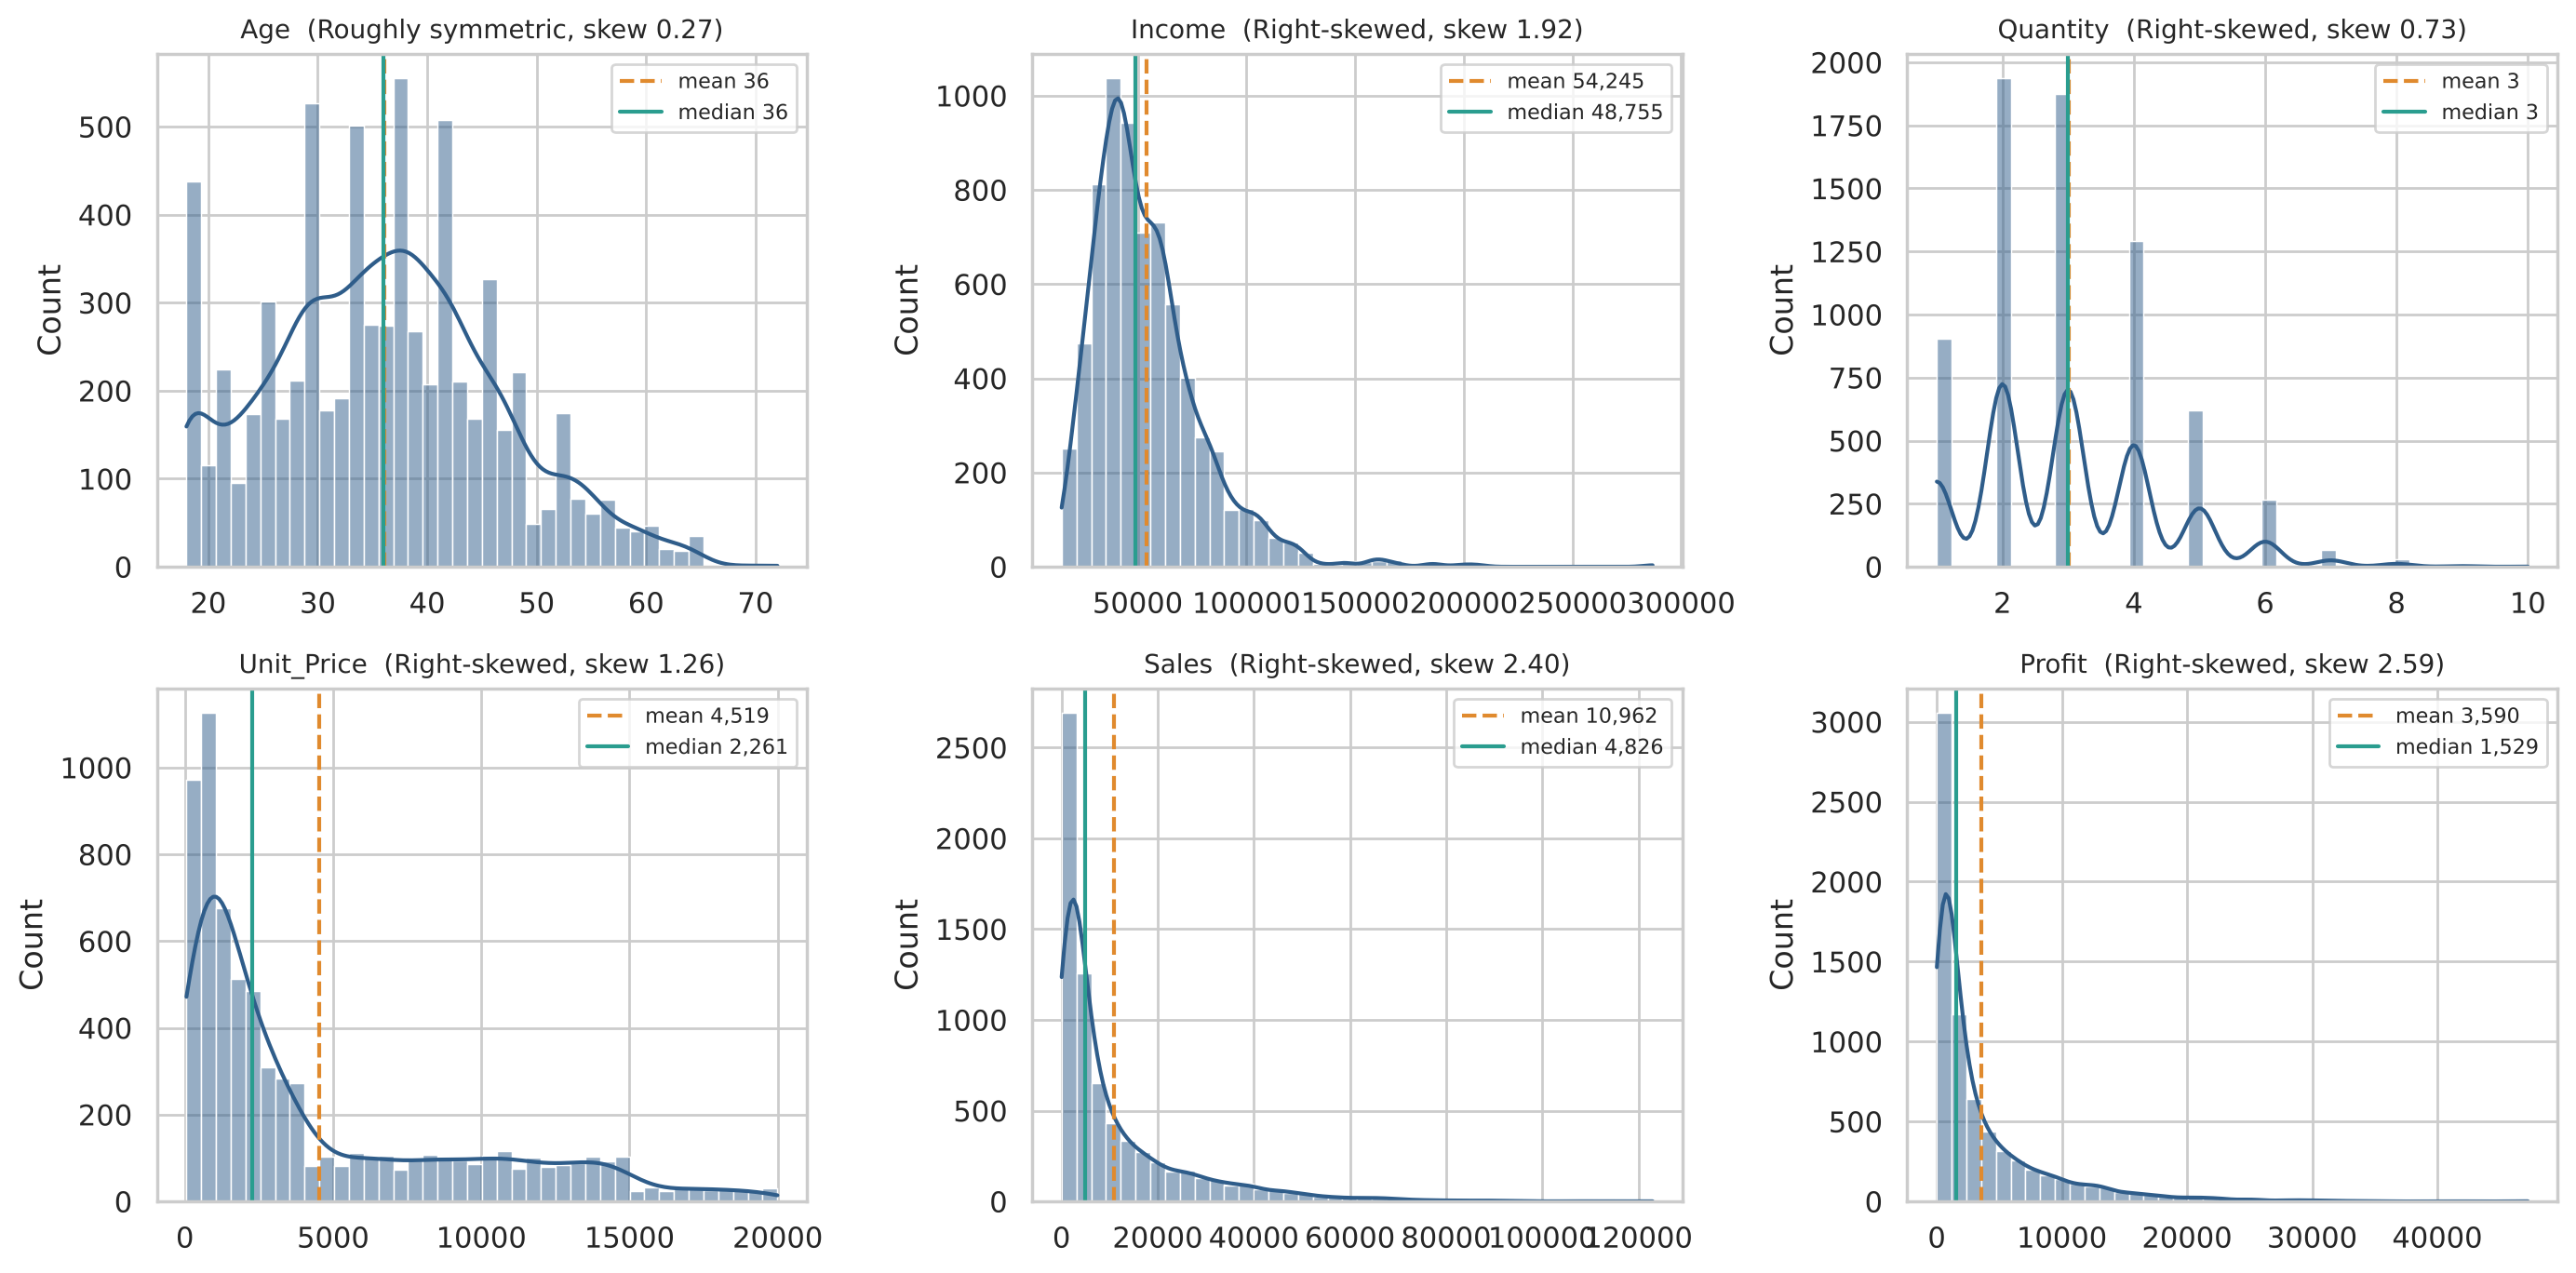

,skewness,shape,mean,median
Age,0.27,Roughly symmetric,36.05,36.00
Income,1.92,Right-skewed,"54,245.33","48,754.85"
Quantity,0.73,Right-skewed,3.01,3.00
Unit_Price,1.26,Right-skewed,"4,519.23","2,261.47"
Sales,2.40,Right-skewed,"10,961.60","4,825.56"
Profit,2.59,Right-skewed,"3,589.70","1,528.70"


In [31]:
def shape_label(sk):
    if sk > 0.5: return "Right-skewed"
    if sk < -0.5: return "Left-skewed"
    return "Roughly symmetric"

num_plot = ["Age", "Income", "Quantity", "Unit_Price", "Sales", "Profit"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num_plot):
    sns.histplot(df[c], bins=40, kde=True, color=BLUE, ax=ax, edgecolor="white")
    ax.axvline(df[c].mean(), color=ORANGE, ls="--", lw=1.5, label=f"mean {df[c].mean():,.0f}")
    ax.axvline(df[c].median(), color=TEAL, ls="-", lw=1.5, label=f"median {df[c].median():,.0f}")
    ax.set_title(f"{c}  ({shape_label(df[c].skew())}, skew {df[c].skew():.2f})", fontsize=10)
    ax.set_xlabel(""); ax.legend(fontsize=8)
save("02_distributions")

skew_table = pd.DataFrame({"skewness": df[num_plot].skew(),
                           "shape": [shape_label(s) for s in df[num_plot].skew()],
                           "mean": df[num_plot].mean(), "median": df[num_plot].median()})
skew_table

In [32]:
KEY['skew'] = {c: round(float(df[c].skew()), 2) for c in num_plot}

**What the shapes mean for the business** (numbers from the table above)
- **Age** is roughly symmetric around the mid-30s, so the mean is a fair "typical age".
- **Income** is right-skewed: the mean is higher than the median because a few very high earners pull it up. The median is the honest "typical customer income".
- **Sales** and **Profit** are strongly right-skewed: most orders are small, a minority of big furniture/electronics orders are very large. If a manager hears only the average, they will overestimate what a normal order is worth.
- **Unit_Price** is right-skewed too, because the catalogue mixes cheap groceries with expensive furniture.
- **Quantity** is a small whole number (1 to 10), only mildly right-skewed, and bounded so it has no heavy tail.

### 4.3 Categorical variables: frequency and proportion

--- Region ---
        count  percent
Region                
West     1798    25.69
East     1765    25.21
South    1761    25.16
North    1676    23.94 

--- Product_Category ---
                  count  percent
Product_Category                
Electronics        1975    28.21
Grocery            1669    23.84
Clothing           1533    21.90
Furniture           979    13.99
Office Supplies     844    12.06 

--- Customer_Segment ---
                  count  percent
Customer_Segment                
Consumer           3840    54.86
Corporate          2114    30.20
Home Office        1046    14.94 



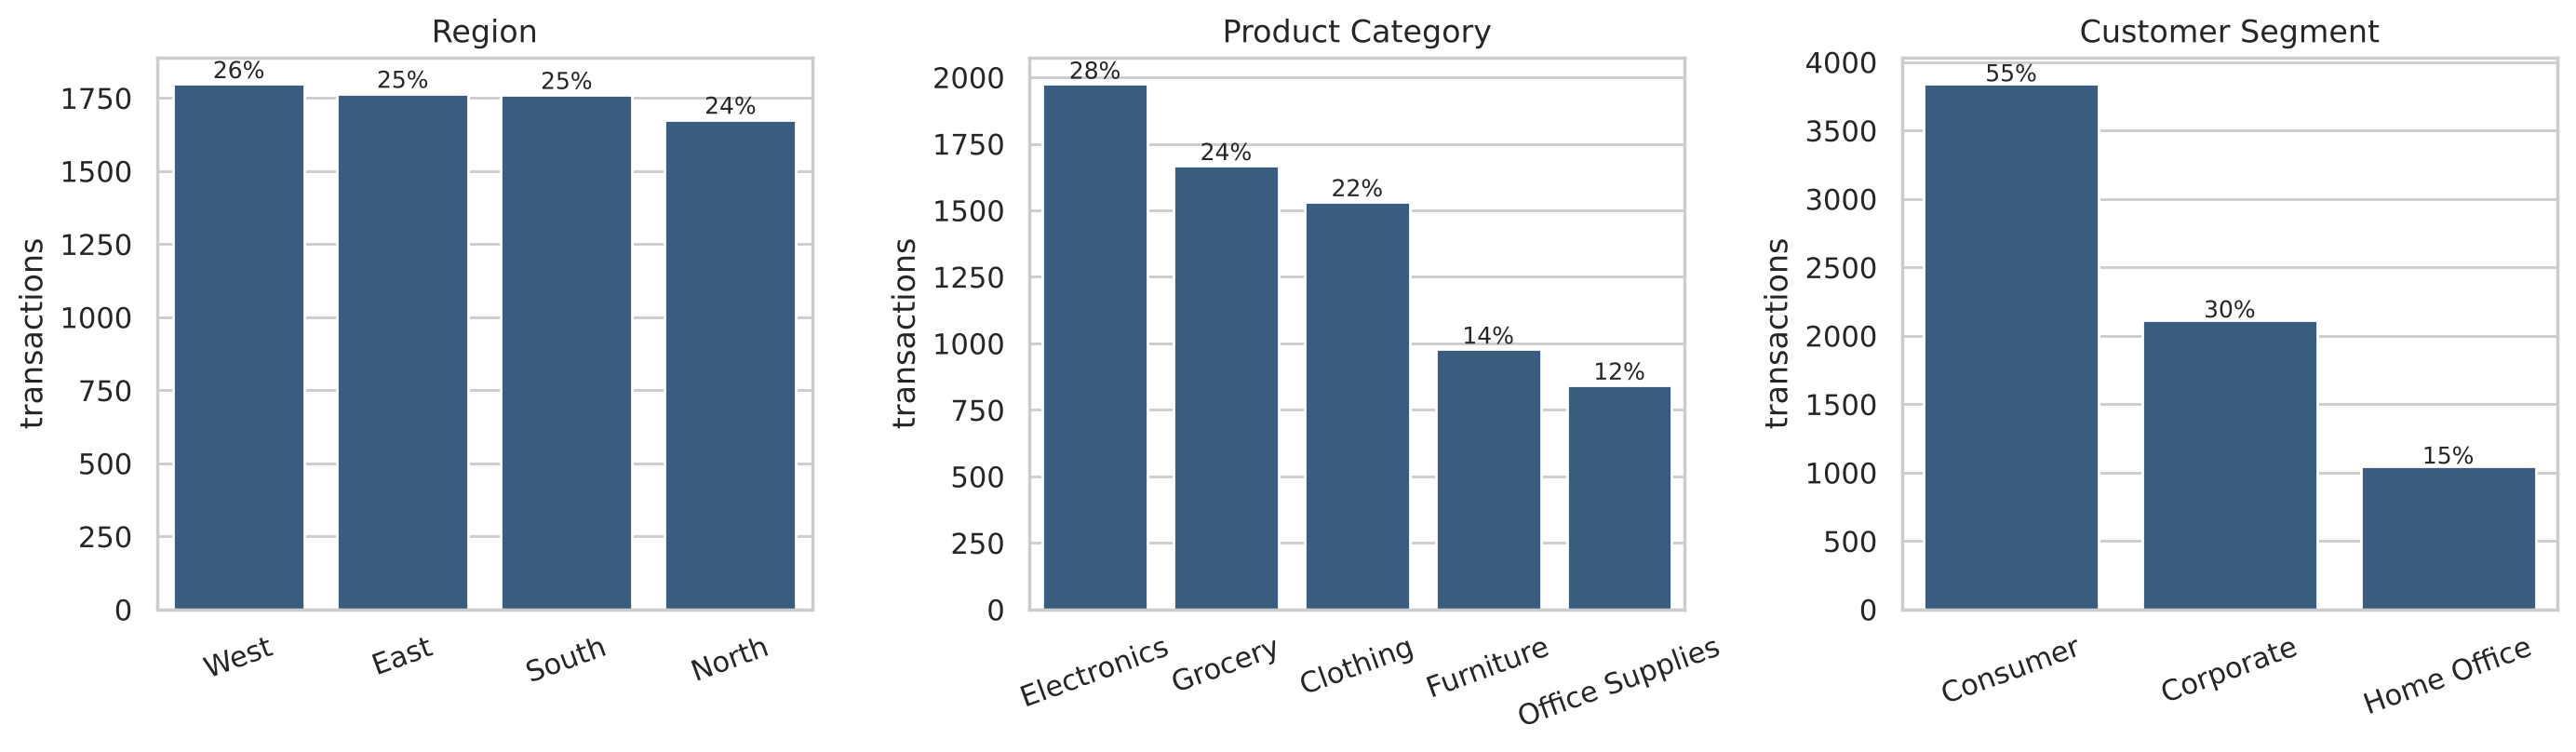

In [33]:
def freq_table(col):
    t = df[col].value_counts().to_frame("count")
    t["percent"] = (t["count"] / t["count"].sum() * 100).round(2)
    return t

cat_cols = ["Region", "Product_Category", "Customer_Segment"]
for c in cat_cols:
    print(f"--- {c} ---"); print(freq_table(c), "\n")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, c in zip(axes, cat_cols):
    t = freq_table(c)
    sns.barplot(x=t.index, y=t["count"], color=BLUE, ax=ax)
    for i, (cnt, pct) in enumerate(zip(t["count"], t["percent"])):
        ax.text(i, cnt + 20, f"{pct:.0f}%", ha="center", fontsize=9)
    ax.set_title(c.replace("_", " ")); ax.set_xlabel(""); ax.set_ylabel("transactions")
    ax.tick_params(axis="x", rotation=20)
save("03_categorical")
KEY["freq"] = {c: freq_table(c)["percent"].to_dict() for c in cat_cols}

In [34]:
# a few more categorical columns, for completeness
for c in ["Gender", "Payment_Method", "Delivery_Mode", "Satisfaction_Level", "Returned"]:
    print(f"--- {c} ---"); print(freq_table(c), "\n")
KEY["freq"].update({c: freq_table(c)["percent"].to_dict() for c in ["Gender", "Payment_Method", "Delivery_Mode", "Satisfaction_Level", "Returned"]})

--- Gender ---
        count  percent
Gender                
Female   3675    52.50
Male     3325    47.50 

--- Payment_Method ---
                  count  percent
Payment_Method                  
Net Banking        1433    20.47
Debit Card         1417    20.24
Cash on Delivery   1408    20.11
UPI                1405    20.07
Credit Card        1337    19.10 

--- Delivery_Mode ---
               count  percent
Delivery_Mode                
Standard        4249    60.70
Express         2055    29.36
Same-Day         696     9.94 

--- Satisfaction_Level ---
                    count  percent
Satisfaction_Level                
High                 2549    36.41
Medium               2518    35.97
Low                  1758    25.11
Not Provided          175     2.50 

--- Returned ---
          count  percent
Returned                
No         6120    87.43
Yes         880    12.57 



**Reading:** the four regions each hold roughly a quarter of the transactions, so no region dominates the volume. Electronics and Grocery are the busiest categories by count. Consumers are the biggest segment by far (more than half of transactions), followed by Corporate. Payment methods are almost evenly split across five options, so there is no clear favourite.

## 5. Outlier detection

I use two methods: the **IQR rule** (below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR) and the **Z-score rule** (|z| > 3).

In [35]:
out_vars = ["Sales", "Profit", "Age", "Income"]
rows = []
for c in out_vars:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = (df[c] < lo) | (df[c] > hi)
    z = (df[c] - df[c].mean()) / df[c].std()
    z_mask = z.abs() > 3
    rows.append({"variable": c, "lower_fence": lo, "upper_fence": hi,
                 "IQR_outliers": iqr_mask.sum(), "IQR_%": iqr_mask.mean() * 100,
                 "Z_outliers": z_mask.sum(), "Z_%": z_mask.mean() * 100})
    df[f"{c}_Outlier"] = iqr_mask      # flag columns: nothing is deleted
outlier_table = pd.DataFrame(rows).set_index("variable")
outlier_table

,lower_fence,upper_fence,IQR_outliers,IQR_%,Z_outliers,Z_%
variable,,,,,,
Sales,"-16,604.37","32,515.17",632,9.03,153,2.19
Profit,"-5,364.72","10,472.09",640,9.14,160,2.29
Age,8.00,64.00,10,0.14,6,0.09
Income,"-5,854.93","108,617.02",228,3.26,81,1.16


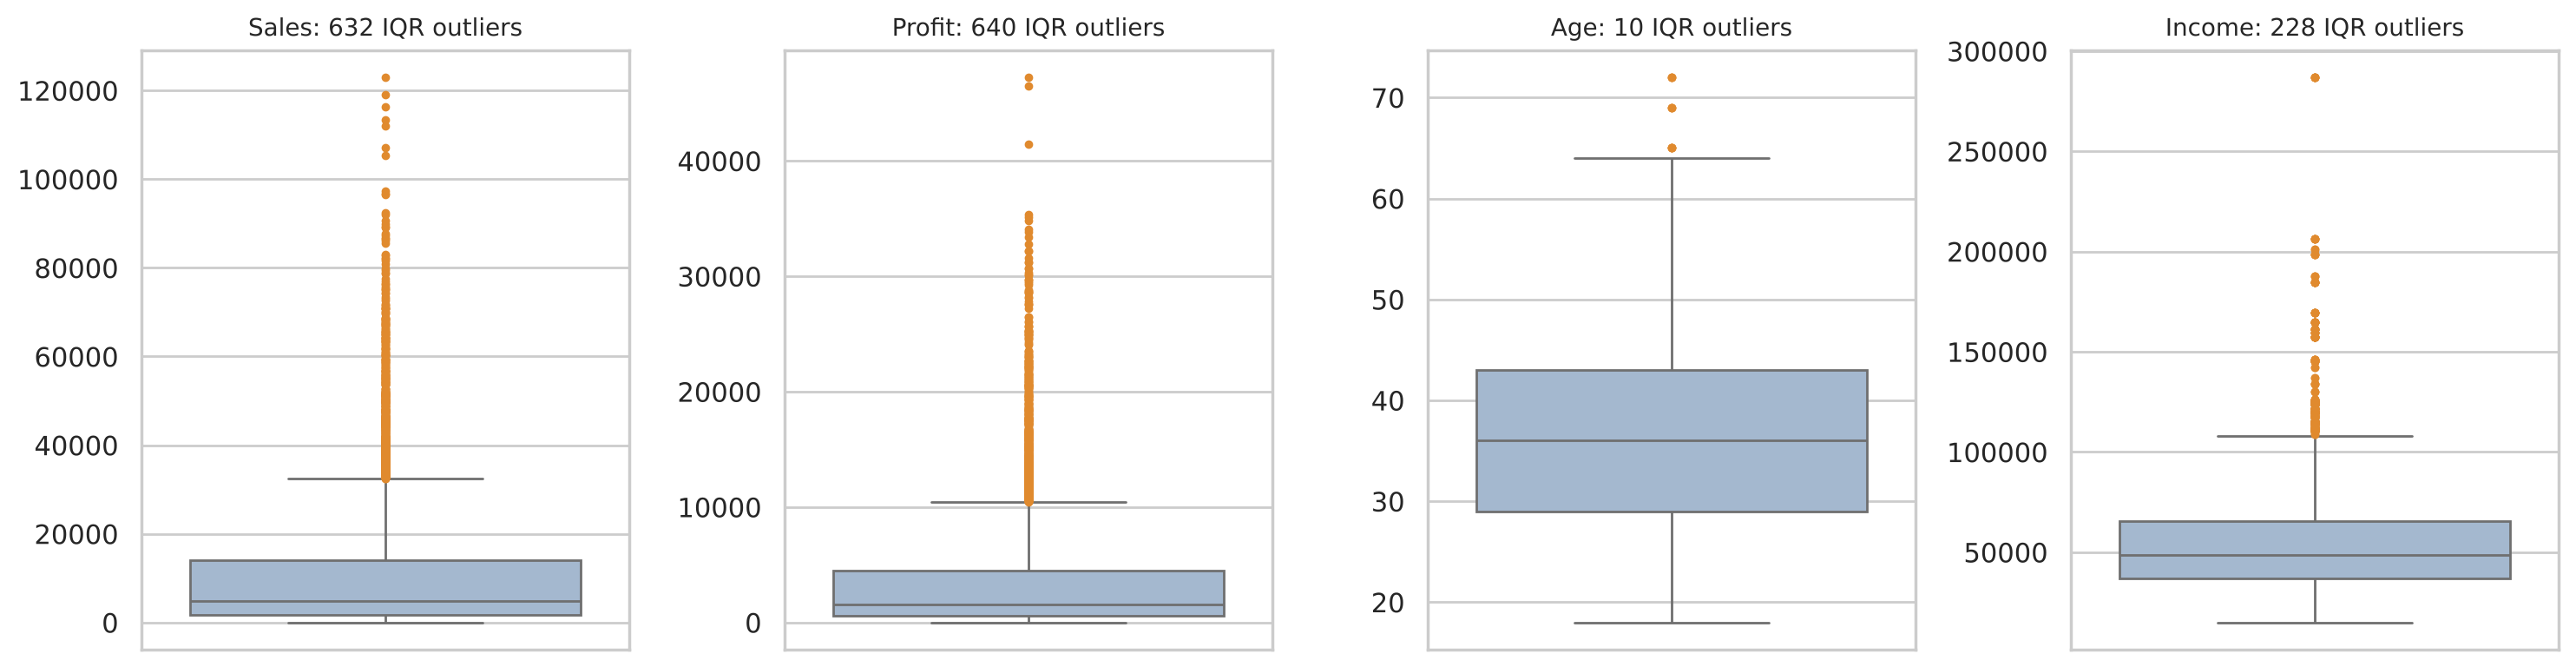

In [36]:
outlier_table.round(2).to_csv("outputs/outlier_summary.csv")
KEY["outliers"] = outlier_table.round(2).to_dict()

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, c in zip(axes, out_vars):
    sns.boxplot(y=df[c], color="#9DB8D6", ax=ax, fliersize=2.5, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": ORANGE})
    ax.set_title(f"{c}: {int(outlier_table.loc[c, 'IQR_outliers'])} IQR outliers", fontsize=10); ax.set_ylabel("")
save("04_outliers_boxplots")

### Are the outliers real or errors? Looking at the evidence

In [37]:
# SALES / PROFIT: if these are genuine big orders, they should sit in expensive categories,
# have normal margins and obey the Sales formula. If they were typing errors they would not.
s_out = df[df.Sales_Outlier]
print("Sales outliers:", len(s_out))
print("\nCategory mix of Sales outliers (%):")
print((s_out.Product_Category.value_counts(normalize=True) * 100).round(1))
print("\nMargin range of outliers :", round((s_out.Profit / s_out.Sales).min() * 100, 1), "% to", round((s_out.Profit / s_out.Sales).max() * 100, 1), "%")
print("Margin range of all rows :", round((df.Profit / df.Sales).min() * 100, 1), "% to", round((df.Profit / df.Sales).max() * 100, 1), "%")
print("Quantity range of outliers:", s_out.Quantity.min(), "to", s_out.Quantity.max())
print("Formula holds for all outliers:", ((s_out.Quantity * s_out.Unit_Price * (1 - s_out.Discount) - s_out.Sales).abs() <= 1).all())
KEY["sales_outlier_cat"] = (s_out.Product_Category.value_counts(normalize=True) * 100).round(1).to_dict()
KEY["sales_outlier_share_of_revenue"] = round(float(s_out.Sales.sum() / df.Sales.sum() * 100), 1)
print("\nShare of total revenue from these orders:", KEY["sales_outlier_share_of_revenue"], "%")

Sales outliers: 632

Category mix of Sales outliers (%):
Product_Category
Electronics   52.50
Furniture     47.50
Name: proportion, dtype: float64

Margin range of outliers : 20.1 % to 45.0 %
Margin range of all rows : 20.0 % to 45.0 %
Quantity range of outliers: 2 to 10
Formula holds for all outliers: True

Share of total revenue from these orders: 39.6 %


In [38]:
# AGE after cleaning, and INCOME
a_out = df[df.Age_Outlier]
print("Age outliers:", len(a_out), "| ages:", sorted(a_out.Age.unique()))

i_out = df[df.Income_Outlier]
print("\nIncome outliers (after correcting the 9 inflated values):", len(i_out), "rows from", i_out.Customer_ID.nunique(), "customers")
# genuine high earners should show the SAME income on every one of their orders
by_cust = i_out.groupby("Customer_ID").Income.agg(["count", "nunique", "max"]).sort_values("max", ascending=False)
print("Customers with one consistent income across all orders:", (by_cust["nunique"] == 1).sum(), "of", len(by_cust))
print(by_cust.head(5))

cust_inc = df.groupby("Customer_ID").Income.first()
print("\nCustomers at exactly 15,000:", (cust_inc == 15000).sum(), "(", (df.Income == 15000).sum(), "rows ) | next lowest income:", round(cust_inc[cust_inc > 15000].min(), 2))
KEY["income_floor_rows"] = int((df.Income == 15000).sum())

Age outliers: 10 | ages: [np.int64(65), np.int64(69), np.int64(72)]

Income outliers (after correcting the 9 inflated values): 228 rows from 51 customers
Customers with one consistent income across all orders: 51 of 51
             count  nunique        max
Customer_ID                           
CUST11295        5        1 286,876.47
CUST10015        5        1 206,261.16
CUST10357        2        1 201,186.34
CUST10705        4        1 198,682.50
CUST10921        3        1 187,843.90

Customers at exactly 15,000: 7 ( 32 rows ) | next lowest income: 15185.61


**Decisions**
- **Sales and Profit (about 9% of rows flagged): genuine.** They sit entirely in Furniture and Electronics (and bring about 40% of all revenue), which have high unit prices, the margins are in the same 20-45% band as every other order, quantity stays within 1-10, and the Sales formula holds exactly. They are real large orders, not errors. They are **kept** and flagged (`Sales_Outlier`, `Profit_Outlier`). I use median and percentiles when describing a "typical" order.
- **Age: genuine.** After fixing the impossible ages, the few IQR flags are customers aged 65 to 72, which is perfectly plausible.
- **Income: two different stories.** Nine rows were *errors*: an income 10-15 times the same customer's income on all other orders. I corrected those in Section 3.4, so they are no longer outliers. The income outliers that remain belong to customers whose high income is the same on every order (the largest is about 287,000), which is consistent with genuine high earners, so I **keep** them and flag `Income_Outlier`. One more oddity: 7 customers (32 rows) have exactly 15,000 and the next lowest income is 15,186, which looks like a minimum floor in the source data. I leave it as given and use the median rather than the mean for income.
- **Z-score vs IQR:** Z-score flags fewer points than IQR because the extreme values inflate the standard deviation, which is another reason to prefer IQR for skewed data.

## 6. Feature engineering and business questions

### 6.1 New calculated columns

In [39]:
# 1. Profit_Margin: share of each sale that is profit (in %)
df["Profit_Margin"] = (df.Profit / df.Sales * 100).round(2)

# 2. Delivery_Days: how long the order took to arrive
df["Delivery_Days"] = (df.Delivery_Date - df.Order_Date).dt.days

# 3. Revenue_per_Customer: total money each customer has spent with the company
df["Revenue_per_Customer"] = df.groupby("Customer_ID").Sales.transform("sum").round(2)

# 4. Order_Year, Order_Month, Order_Quarter: for time trends
df["Order_Year"] = df.Order_Date.dt.year
df["Order_Month"] = df.Order_Date.dt.month
df["Order_Quarter"] = "Q" + df.Order_Date.dt.quarter.astype(str)

# 5. Discount_Band: buckets so discounts are easier to compare
df["Discount_Band"] = pd.cut(df.Discount, bins=[-0.001, 0.10, 0.20, 0.30, 0.50],
                             labels=["0-10%", "10-20%", "20-30%", "30-50%"])

# 6. Age_Group
df["Age_Group"] = pd.cut(df.Age, bins=[17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])

# 7. Order_Value_Band: small / medium / large order using quartiles of Sales
df["Order_Value_Band"] = pd.qcut(df.Sales, q=4, labels=["Small", "Medium", "Large", "Very Large"])

df[["Profit_Margin", "Delivery_Days", "Revenue_per_Customer", "Order_Quarter", "Discount_Band", "Age_Group", "Order_Value_Band"]].head()

,Profit_Margin,Delivery_Days,Revenue_per_Customer,Order_Quarter,Discount_Band,Age_Group,Order_Value_Band
0,33.51,6.00,"5,003.25",Q4,30-50%,36-45,Small
1,26.98,4.00,"74,411.80",Q3,10-20%,36-45,Very Large
2,39.03,8.00,"100,342.46",Q1,0-10%,36-45,Medium
3,36.57,4.00,"29,951.36",Q2,30-50%,26-35,Small
4,33.62,7.00,"21,572.93",Q3,20-30%,26-35,Large


In [40]:
print(df[["Profit_Margin", "Delivery_Days", "Revenue_per_Customer"]].describe())
print("\nDelivery_Days values (should have no negatives):", df.Delivery_Days.min(), "to", df.Delivery_Days.max())

       Profit_Margin  Delivery_Days  Revenue_per_Customer
count       7,000.00       6,880.00              7,000.00
mean           32.63           5.65             58,627.35
std             7.21           2.82             41,938.58
min            20.01           1.00                157.81
25%            26.46           4.00             27,254.94
50%            32.65           6.00             50,108.64
75%            39.01           8.00             80,183.94
max            45.00          17.00            254,002.26

Delivery_Days values (should have no negatives): 1.0 to 17.0


### 6.2 Business questions (groupby and aggregation)

**Q1. Which region has the highest average order value?**

        orders  avg_order_value  median_order   total_sales  share_of_sales_%
Region                                                                       
East      1765        11,341.75      5,029.99 20,018,192.35             26.09
West      1798        10,989.43      4,872.94 19,758,995.56             25.75
North     1676        10,777.98      4,628.11 18,063,891.81             23.54
South     1761        10,726.92      4,747.23 18,890,109.55             24.62


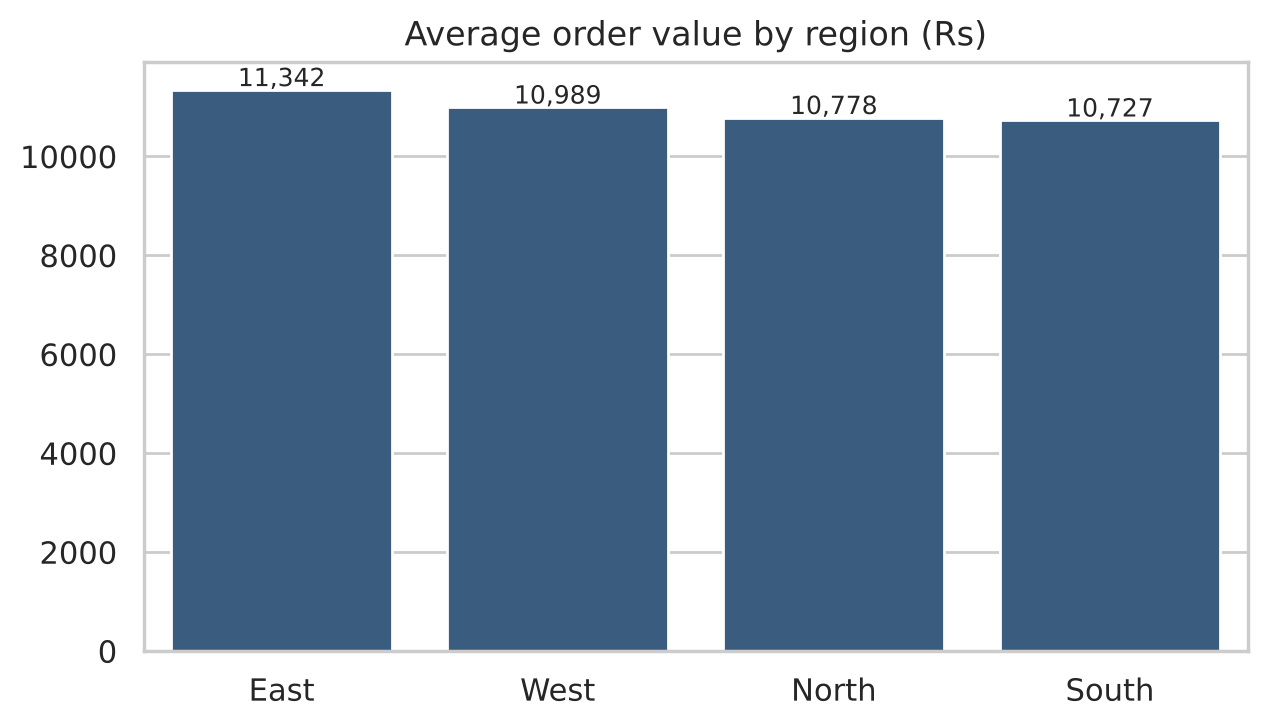

In [41]:
q1 = df.groupby("Region").agg(orders=("Sales", "count"), avg_order_value=("Sales", "mean"),
                              median_order=("Sales", "median"), total_sales=("Sales", "sum")).sort_values("avg_order_value", ascending=False)
q1["share_of_sales_%"] = q1.total_sales / q1.total_sales.sum() * 100
print(q1)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.barplot(x=q1.index, y=q1.avg_order_value, color=BLUE, ax=ax)
for i, v in enumerate(q1.avg_order_value): ax.text(i, v + 80, f"{v:,.0f}", ha="center", fontsize=9)
ax.set_title("Average order value by region (Rs)"); ax.set_xlabel(""); ax.set_ylabel("")
save("05_q1_region_aov")
KEY["q1"] = q1.round(2).reset_index().to_dict("records")

**Answer:** East has the highest average order value (Rs 11,342), South the lowest (Rs 10,727).
**Implication:** the gap is only about 6%, and the medians are even closer (Rs 4,600 to 5,000). Regions are nearly identical in order size, so a region-specific pricing or bundling strategy is not justified by this data. East also holds the largest share of sales (26%).

**Q2. Which product category has the lowest profit margin?**

                   total_sales  total_profit  avg_order_margin  \
Product_Category                                                 
Clothing          7,781,680.39  2,521,027.84             32.28   
Office Supplies   2,566,182.51    832,190.36             32.78   
Grocery           2,685,875.10    874,840.19             32.42   
Furniture        26,057,893.88  8,547,604.77             32.92   
Electronics      37,639,557.39 12,352,219.50             32.87   

                  weighted_margin_%  
Product_Category                     
Clothing                      32.40  
Office Supplies               32.43  
Grocery                       32.57  
Furniture                     32.80  
Electronics                   32.82  


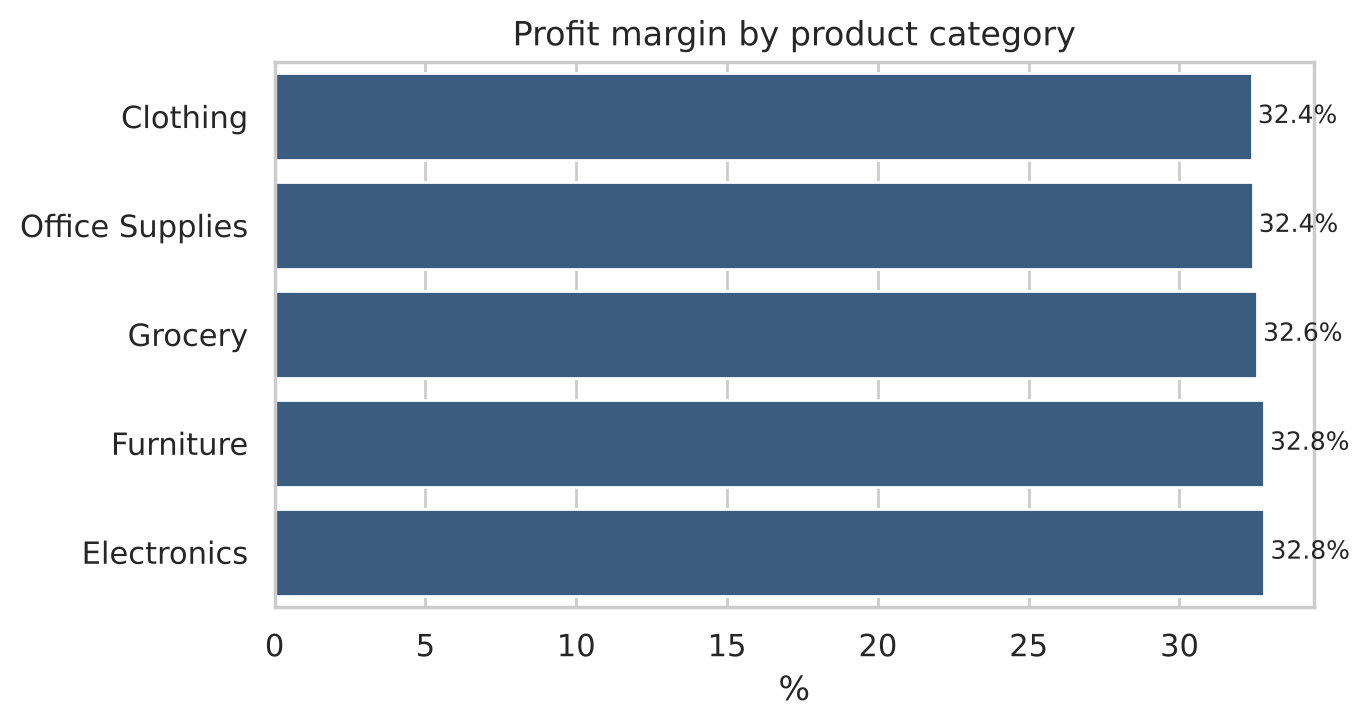

In [42]:
# margin of a category = total profit / total sales (a weighted margin). The simple average of
# per-order margins can be different, so I show both.
q2 = df.groupby("Product_Category").agg(total_sales=("Sales", "sum"), total_profit=("Profit", "sum"),
                                        avg_order_margin=("Profit_Margin", "mean"))
q2["weighted_margin_%"] = q2.total_profit / q2.total_sales * 100
q2 = q2.sort_values("weighted_margin_%")
print(q2)
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.barplot(x=q2["weighted_margin_%"], y=q2.index, color=BLUE, ax=ax)
for i, v in enumerate(q2["weighted_margin_%"]): ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Profit margin by product category"); ax.set_xlabel("%"); ax.set_ylabel("")
save("06_q2_category_margin")
KEY["q2"] = q2.round(2).reset_index().to_dict("records")

**Answer:** Clothing has the lowest margin (32.4%), Electronics the highest (32.8%).
**Implication:** all five categories are within 0.4 percentage points of each other. No category is a margin problem. Where the money is made is decided by volume and price, not margin: Electronics and Furniture are 42% of orders but bring 83% of sales and profit.

**Q3. Which customer segment brings the most revenue, and how big is its average order?**

In [43]:
q3 = df.groupby("Customer_Segment").agg(orders=("Sales", "count"), total_sales=("Sales", "sum"),
                                        avg_order_value=("Sales", "mean"), total_profit=("Profit", "sum"))
q3["share_of_sales_%"] = q3.total_sales / q3.total_sales.sum() * 100
q3["share_of_orders_%"] = q3.orders / q3.orders.sum() * 100
q3 = q3.sort_values("total_sales", ascending=False)
print(q3)
KEY["q3"] = q3.round(2).reset_index().to_dict("records")

                  orders   total_sales  avg_order_value  total_profit  \
Customer_Segment                                                        
Consumer            3840 41,718,896.33        10,864.30 13,703,577.36   
Corporate           2114 23,551,202.48        11,140.59  7,665,257.93   
Home Office         1046 11,461,090.46        10,957.07  3,759,047.37   

                  share_of_sales_%  share_of_orders_%  
Customer_Segment                                       
Consumer                     54.37              54.86  
Corporate                    30.69              30.20  
Home Office                  14.94              14.94  


**Answer:** Consumers bring the most revenue (54% of sales), then Corporate (31%) and Home Office (15%).
**Implication:** revenue share almost exactly matches order share, and Corporate's average order (Rs 11,141) is only about 2.5% above Consumer's (Rs 10,864). Corporate customers are *not* the big-ticket buyers one might assume, so a separate corporate sales push is not obviously worth more per order.

**Q4. Does the delivery mode actually change delivery time, and how do customers rate each mode?**

In [44]:
q4 = df.groupby("Delivery_Mode").agg(orders=("Sales", "count"), avg_days=("Delivery_Days", "mean"),
                                     median_days=("Delivery_Days", "median"),
                                     avg_rating=("Customer_Rating", "mean"),
                                     return_rate=("Returned", lambda s: (s == "Yes").mean() * 100))
print(q4)
KEY["q4"] = q4.round(2).reset_index().to_dict("records")

               orders  avg_days  median_days  avg_rating  return_rate
Delivery_Mode                                                        
Express          2055      5.63         6.00        3.11        12.41
Same-Day          696      5.77         6.00        3.12        12.79
Standard         4249      5.65         6.00        3.08        12.61


**Answer:** no. Express (5.6 days), Standard (5.7 days) and Same-Day (5.8 days) all take about the same time. Ratings (3.1) and return rates (12.4% to 12.8%) are also the same.
**Implication:** this is the most actionable finding. Customers who pay for Express or Same-Day are not getting a faster delivery, and a Same-Day order averaging nearly 6 days is a broken promise. Either the delivery-mode field is not being recorded properly or the premium services are not performing. It needs to be checked with the logistics team.

**Q5. Which categories have the highest return rate?**

In [45]:
q5 = df.groupby("Product_Category").agg(orders=("Returned", "count"),
                                        returns=("Returned", lambda s: (s == "Yes").sum()),
                                        return_rate=("Returned", lambda s: (s == "Yes").mean() * 100)).sort_values("return_rate", ascending=False)
print(q5)
# money lost to returns, assuming returned orders refund the full sale value
returned_value = df.loc[df.Returned == "Yes", "Sales"].sum()
print("\nOverall return rate: %.1f%%" % ((df.Returned == "Yes").mean() * 100))
print("Value of returned orders: Rs %s (%.1f%% of total sales)" % (f"{returned_value:,.0f}", returned_value / df.Sales.sum() * 100))
KEY["q5"] = q5.round(2).reset_index().to_dict("records")
KEY["returned_value"] = round(float(returned_value), 0); KEY["returned_value_pct"] = round(float(returned_value / df.Sales.sum() * 100), 2)
KEY["overall_return_rate"] = round(float((df.Returned == "Yes").mean() * 100), 2)

                  orders  returns  return_rate
Product_Category                              
Clothing            1533      207        13.50
Furniture            979      129        13.18
Grocery             1669      208        12.46
Electronics         1975      239        12.10
Office Supplies      844       97        11.49

Overall return rate: 12.6%
Value of returned orders: Rs 9,037,761 (11.8% of total sales)


**Answer:** Clothing (13.5%) and Furniture (13.2%) have the highest return rates; Office Supplies the lowest (11.5%). Overall, 12.6% of orders are returned, worth about 11.8% of total sales.
**Implication:** roughly one order in eight comes back. The gap between categories is small, so returns are a company-wide issue and not one product line's fault. Clothing's return rate is a familiar pattern (size/fit), while Furniture returns are expensive because each order is high value.

**Q6. How did sales change between 2023 and 2024, quarter by quarter?**

   Order_Year Order_Quarter  orders        sales       profit
0        2023            Q1     879 9,738,584.26 3,096,318.88
1        2023            Q2     893 9,881,386.42 3,207,847.13
2        2023            Q3     893 9,697,143.43 3,156,010.77
3        2023            Q4     860 9,338,525.18 3,049,332.53
4        2024            Q1     894 9,427,476.64 3,124,966.54
5        2024            Q2     835 8,978,641.55 2,943,758.79
6        2024            Q3     852 9,704,033.14 3,223,747.65
7        2024            Q4     894 9,965,398.65 3,325,900.37

             orders         sales        profit  growth_% vs prev
Order_Year                                                      
2023          3525 38,655,639.29 12,509,509.31               NaN
2024          3475 38,075,549.98 12,618,373.35             -1.50


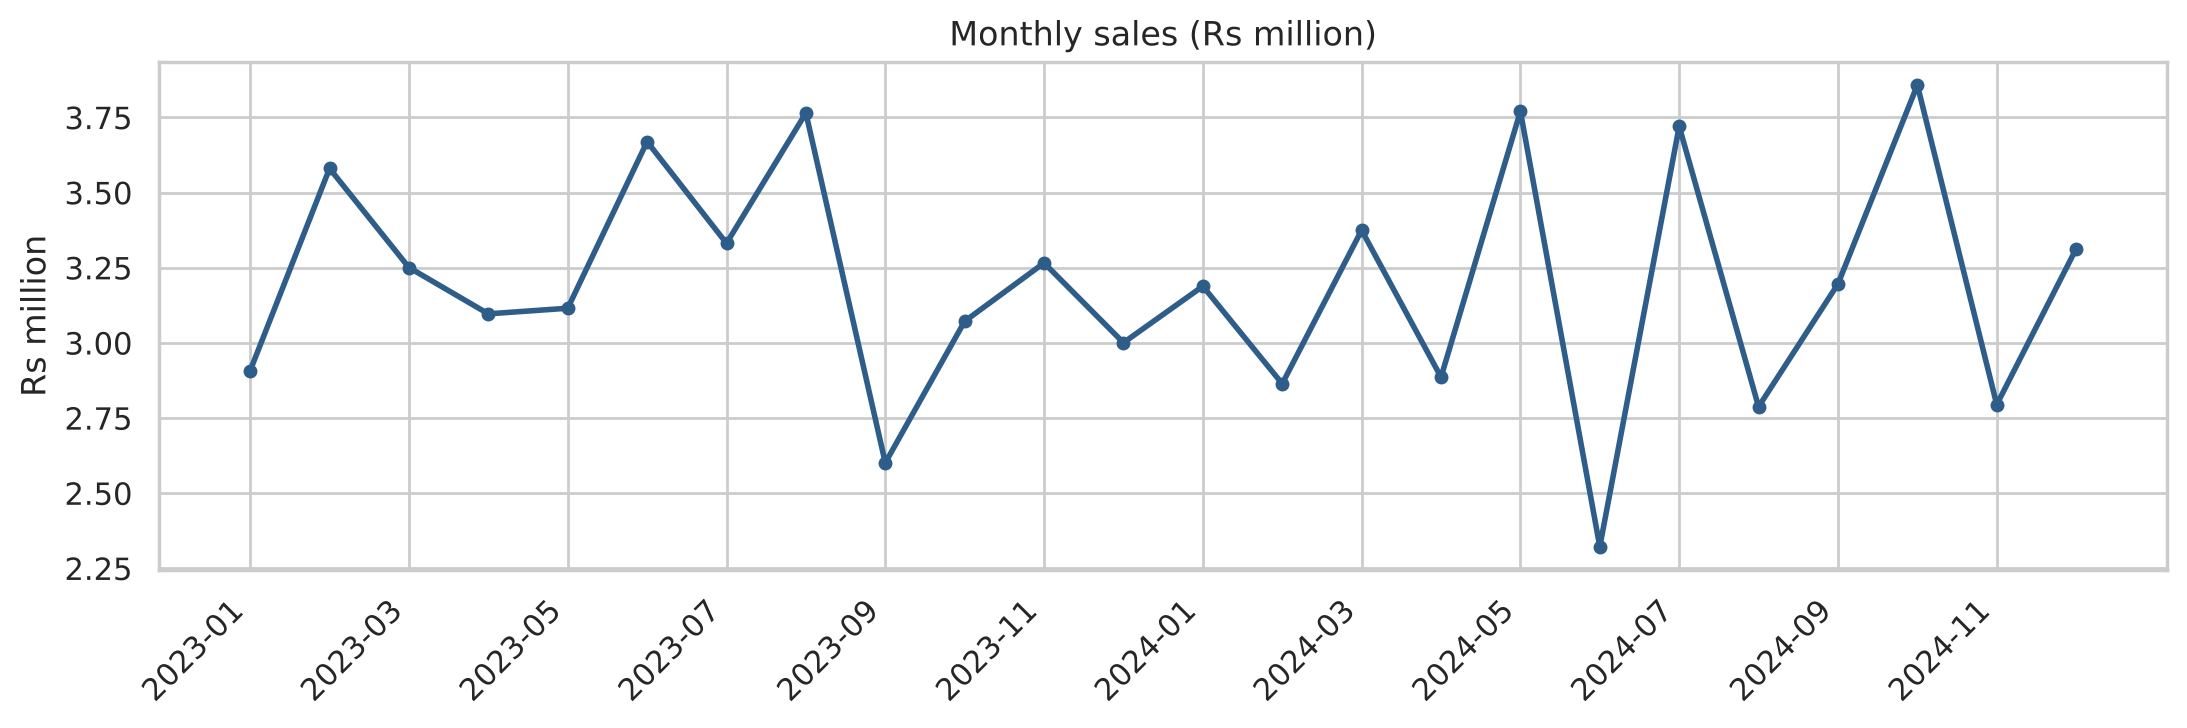

In [46]:
q6 = df.groupby(["Order_Year", "Order_Quarter"]).agg(orders=("Sales", "count"), sales=("Sales", "sum"), profit=("Profit", "sum")).reset_index()
print(q6)
yearly = df.groupby("Order_Year").agg(orders=("Sales", "count"), sales=("Sales", "sum"), profit=("Profit", "sum"))
yearly["growth_% vs prev"] = yearly.sales.pct_change() * 100
print("\n", yearly)

monthly = df.groupby(df.Order_Date.dt.to_period("M")).Sales.sum()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(monthly.index.astype(str), monthly.values / 1e6, color=BLUE, marker="o", lw=2, ms=4)
ax.set_title("Monthly sales (Rs million)"); ax.set_xlabel(""); ax.set_ylabel("Rs million")
ax.set_xticks(range(0, len(monthly), 2)); ax.set_xticklabels(monthly.index.astype(str)[::2], rotation=45, ha="right")
save("07_q6_monthly_sales")
KEY["q6_yearly"] = yearly.round(2).reset_index().to_dict("records")
KEY["q6_quarterly"] = q6.round(2).to_dict("records")

**Answer:** sales were flat. 2024 (Rs 38.08 million) was 1.5% below 2023 (Rs 38.66 million). Q2 2024 was the weakest quarter (Rs 8.98 million), and Q4 2024 the strongest (Rs 9.97 million).
**Implication:** the business is not growing. The Q2 2024 dip followed by a strong second half is encouraging, but a full year of flat sales means growth has to come from somewhere else, such as more orders per customer or new customers. The data shows no strong seasonal pattern.

**Q7. Do bigger discounts earn more sales, or just destroy margin?**

In [47]:
q7 = df.groupby("Discount_Band").agg(orders=("Sales", "count"), avg_quantity=("Quantity", "mean"),
                                     avg_order_value=("Sales", "mean"), weighted_margin=("Profit", "sum"),
                                     sales=("Sales", "sum"), return_rate=("Returned", lambda s: (s == "Yes").mean() * 100))
q7["weighted_margin_%"] = q7.weighted_margin / q7.sales * 100
print(q7.drop(columns=["weighted_margin", "sales"]))
KEY["q7"] = q7.drop(columns=["weighted_margin", "sales"]).round(2).reset_index().to_dict("records")

               orders  avg_quantity  avg_order_value  return_rate  \
Discount_Band                                                       
0-10%            1668          3.01        13,085.47        12.95   
10-20%           2329          3.00        11,541.64        11.29   
20-30%           1679          3.02        10,409.74        14.29   
30-50%           1324          3.00         7,965.40        12.16   

               weighted_margin_%  
Discount_Band                     
0-10%                      32.94  
10-20%                     32.67  
20-30%                     32.64  
30-50%                     32.73  


**Answer:** discounts do not buy bigger baskets. Average quantity per order is 3.0 in every discount band. Orders with 30-50% discount have a much smaller average value (Rs 7,965) than those with 0-10% (Rs 13,085).
**Implication:** customers are not buying more units because of the discount, so deep discounts are giving away price without raising volume. Margin stays about 32.7% in every band, which is unusual for real retail (discounting normally cuts margin). I would verify with finance how `Cost` is recorded before concluding that discounts are free. Orders with 20-30% discount have the highest return rate (14.3%), but I would not read much into one band.

**Q8. How concentrated is revenue among customers? Who are the top 10?**

Customers: 1576
Top 10% of customers (157) bring 26.7% of revenue
Top 20% of customers bring 44.5% of revenue

Top 10 customers:
             orders    revenue  cum_share_%
Customer_ID                                
CUST11430         8 254,002.26         0.33
CUST10354        11 238,064.84         0.64
CUST10459        14 221,690.61         0.93
CUST10302         9 219,114.52         1.22
CUST10970         6 218,118.79         1.50
CUST11150         6 213,584.29         1.78
CUST10594        10 213,154.50         2.06
CUST10080        10 212,963.02         2.33
CUST10654         8 192,677.50         2.58
CUST11543         7 191,698.91         2.83

Customers with a single order: 87 (5.5%)


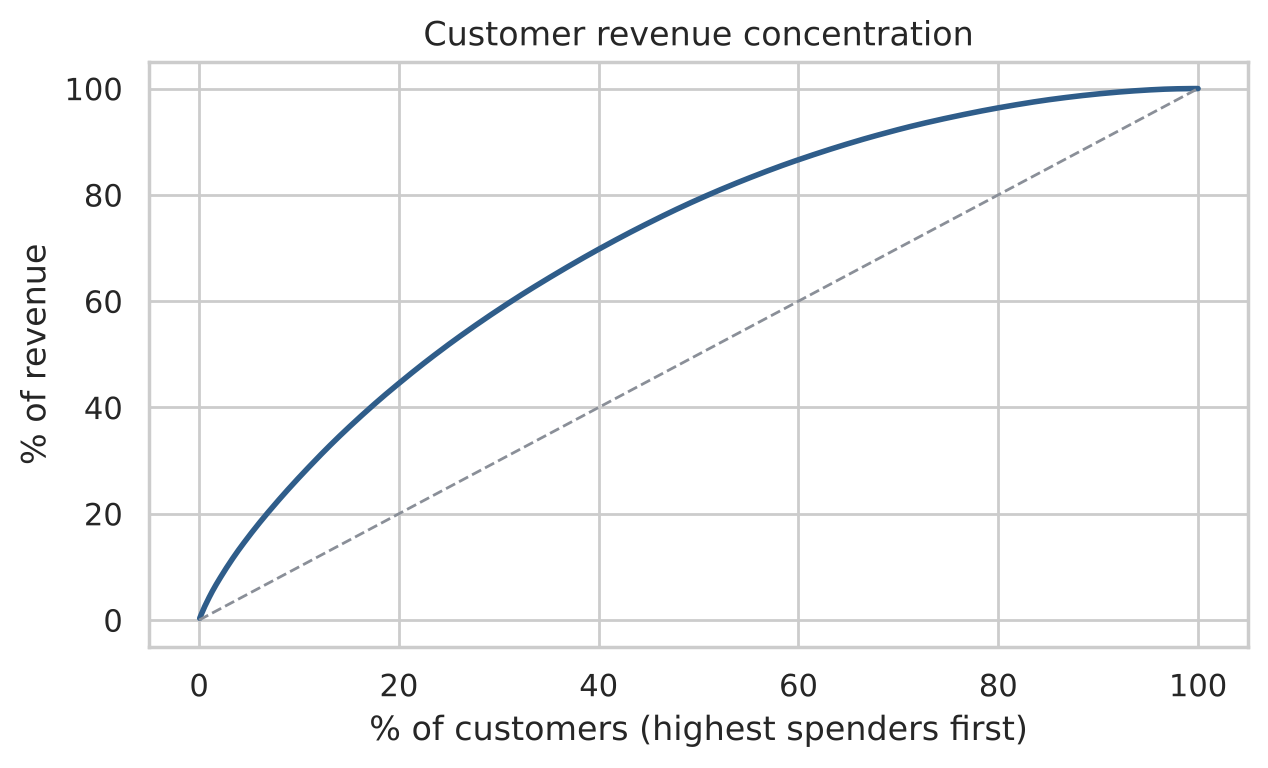

In [48]:
cust = df.groupby("Customer_ID").agg(orders=("Sales", "count"), revenue=("Sales", "sum")).sort_values("revenue", ascending=False)
cust["cum_share_%"] = cust.revenue.cumsum() / cust.revenue.sum() * 100
top10pct = int(len(cust) * 0.10)
print("Customers:", len(cust))
print(f"Top 10% of customers ({top10pct}) bring {cust['cum_share_%'].iloc[top10pct - 1]:.1f}% of revenue")
print(f"Top 20% of customers bring {cust['cum_share_%'].iloc[int(len(cust) * 0.2) - 1]:.1f}% of revenue")
print("\nTop 10 customers:"); print(cust.head(10))
print("\nCustomers with a single order:", (cust.orders == 1).sum(), f"({(cust.orders == 1).mean() * 100:.1f}%)")
KEY["customers"] = int(len(cust))
KEY["top10pct_share"] = round(float(cust["cum_share_%"].iloc[top10pct - 1]), 1)
KEY["top20pct_share"] = round(float(cust["cum_share_%"].iloc[int(len(cust) * 0.2) - 1]), 1)
KEY["single_order_customers_pct"] = round(float((cust.orders == 1).mean() * 100), 1)
KEY["avg_orders_per_customer"] = round(float(cust.orders.mean()), 2)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(np.arange(1, len(cust) + 1) / len(cust) * 100, cust["cum_share_%"].values, color=BLUE, lw=2)
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1)
ax.set_xlabel("% of customers (highest spenders first)"); ax.set_ylabel("% of revenue"); ax.set_title("Customer revenue concentration")
save("08_q8_customer_concentration")

**Answer:** the top 10% of customers bring about 27% of revenue and the top 20% bring about 45%. Only 5.5% of customers ordered just once; the average customer ordered 4.4 times.
**Implication:** revenue is spread fairly widely, so the business is not dependent on a few accounts (a true "80/20" pattern would show the top 20% bringing 80%). Customers come back, which is a strength. The opportunity is to raise order frequency and basket size across the whole base rather than to protect a handful of VIPs.

In [49]:
# one more look: which states sell the most (nested inside Region)
state = df.groupby(["Region", "State"]).agg(sales=("Sales", "sum"), orders=("Sales", "count")).sort_values("sales", ascending=False)
state["share_%"] = state.sales / state.sales.sum() * 100
print(state.head(5)); print("..."); print(state.tail(3))
KEY["state_top"] = state.head(3).round(2).reset_index().to_dict("records")
KEY["state_bottom"] = state.tail(3).round(2).reset_index().to_dict("records")

# payment method vs order value
pay = df.groupby("Payment_Method").agg(orders=("Sales", "count"), aov=("Sales", "mean"), returns=("Returned", lambda s: (s == "Yes").mean() * 100))
print("\n", pay)
KEY["pay"] = pay.round(2).reset_index().to_dict("records")
# rating vs return
print("\nAverage rating by Returned:"); print(df.groupby("Returned").Customer_Rating.mean())
KEY["rating_by_return"] = df.groupby("Returned").Customer_Rating.mean().round(2).to_dict()
print("\nRating missing by Returned (%):"); print(df.groupby("Returned").Rating_Missing.mean() * 100)

                          sales  orders  share_%
Region State                                    
West   Maharashtra 5,769,832.79     478     7.52
East   Odisha      5,383,099.86     464     7.02
West   Gujarat     5,340,495.04     463     6.96
East   West Bengal 5,146,575.10     426     6.71
South  Kerala      4,982,346.88     461     6.49
...
                             sales  orders  share_%
Region State                                       
North  Delhi          4,140,801.28     445     5.40
South  Andhra Pradesh 4,106,054.48     427     5.35
West   Rajasthan      3,941,342.68     392     5.14

                   orders       aov  returns
Payment_Method                             
Cash on Delivery    1408 11,559.30    13.14
Credit Card         1337 10,944.76    11.52
Debit Card          1417 10,935.95    12.14
Net Banking         1433 10,127.40    11.93
UPI                 1405 11,255.33    14.09

Average rating by Returned:
Returned
No    3.23
Yes   2.14
Name: Customer_Rating, 

## 7. Save the cleaned dataset and summary

In [50]:
# column order: original 24 columns first, then flags, then engineered features
orig_cols = list(raw.columns)
flag_cols = ["Delivery_Date_Error", "Rating_Missing", "Sales_Outlier", "Profit_Outlier", "Age_Outlier", "Income_Outlier"]
new_cols = ["Profit_Margin", "Delivery_Days", "Revenue_per_Customer", "Order_Year", "Order_Month", "Order_Quarter",
            "Discount_Band", "Age_Group", "Order_Value_Band"]
final = df[orig_cols + flag_cols + new_cols].copy()
final["Order_Date"] = final.Order_Date.dt.strftime("%Y-%m-%d")
final["Delivery_Date"] = final.Delivery_Date.dt.strftime("%Y-%m-%d")
final.to_csv("outputs/Cleaned_Dataset.csv", index=False)
print("Saved cleaned dataset:", final.shape)

KEY["final_shape"] = list(final.shape)
KEY["final_missing"] = {k: int(v) for k, v in final.isna().sum().items() if v > 0}
KEY["totals"] = {"sales": round(float(df.Sales.sum()), 0), "profit": round(float(df.Profit.sum()), 0),
                 "margin_pct": round(float(df.Profit.sum() / df.Sales.sum() * 100), 2),
                 "aov": round(float(df.Sales.mean()), 0), "median_order": round(float(df.Sales.median()), 0),
                 "avg_delivery_days": round(float(df.Delivery_Days.mean()), 2),
                 "avg_rating": round(float(df.Customer_Rating.mean()), 2)}
with open("outputs/key_numbers.json", "w") as f:
    json.dump(KEY, f, indent=1, default=str)
final.head()

Saved cleaned dataset: (7000, 39)


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned,Delivery_Date_Error,Rating_Missing,Sales_Outlier,Profit_Outlier,Age_Outlier,Income_Outlier,Profit_Margin,Delivery_Days,Revenue_per_Customer,Order_Year,Order_Month,Order_Quarter,Discount_Band,Age_Group,Order_Value_Band
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No,False,False,False,False,False,False,33.51,6.00,"5,003.25",2023,12,Q4,30-50%,36-45,Small
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No,False,False,False,False,False,False,26.98,4.00,"74,411.80",2023,9,Q3,10-20%,36-45,Very Large
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No,False,False,False,False,False,False,39.03,8.00,"100,342.46",2023,1,Q1,0-10%,36-45,Medium
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No,False,False,False,False,False,False,36.57,4.00,"29,951.36",2024,6,Q2,30-50%,26-35,Small
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29,Female,"95,727.49",North,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No,False,False,False,False,False,False,33.62,7.00,"21,572.93",2024,9,Q3,20-30%,26-35,Large


## 8. Summary

| Stage | What I found | What I did |
|---|---|---|
| Missing values | 6 columns with gaps (Customer_Rating the largest) | Discount recomputed exactly, Age/Income filled from the same customer or median, Rating left blank + flagged, Satisfaction labelled "Not Provided", Delivery_Date left blank |
| Duplicates | 61 exact + 23 hidden by date/spelling differences | Fixed dates and spellings first, then dropped all 84 |
| Categories | Gender 8 spellings, Region 12 spellings | Mapped to 2 and 4 clean values |
| Impossible values | 6 bad ages, 6 bad discounts, 15 deliveries before orders, 9 incomes inflated 10-15x on a single order | Ages blanked then imputed, discounts rebuilt from Sales, bad delivery dates blanked and flagged, inflated incomes replaced by the customer's usual income |
| Dates | 4 mixed formats | Each parsed with its own rule into datetime |
| Outliers | Sales/Profit heavy right tails; some Income outliers were errors | Sales/Profit judged genuine, kept, flagged; inflated incomes corrected, remaining income outliers kept and flagged |

The cleaned data is saved as `outputs/Cleaned_Dataset.csv`. The key numbers used in the written report are saved in `outputs/key_numbers.json`.